In [1]:
"""Settings."""
from __future__ import annotations

import hashlib
import json
import pickle
import re
import time
import types
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import signal, linalg, stats
import matplotlib.pyplot as plt
import mne

mne.set_log_level("error")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

SIM_NOTEBOOK = Path("beta_burst_sim.ipynb")         
WORK = Path("pd_beta_three")                        
HEAD_MODEL = "fsaverage"                            
QUICK = False                                       

DATASETS = {
    "sandiego": {
        "root": Path(r"C:\Users\RTX2080Ti\Desktop\Final Data\Parkinson's_Dataset_UO_San_Diego"),
        "naming": "filename",         
        "montage": "1005",             
                                       
        "reference": "Cz",             
        "eog": [],
        "drop": [],
        "blocks": None,                
        "line_freq": 60.0,
    },
    "newmexico": {
        "root": Path(r"C:\Users\RTX2080Ti\Desktop\Final Data\Auditory Oddball\Auditory Oddball - ON OFF"),
        "naming": "newmexico",
        "montage": "1005",
        "reference": "CPz",
        "eog": ["VEOG"],
        "drop": ["FT9", "FT10", "TP9", "TP10"],          
        "blocks": {"EO": "Eyes Open", "EC": "Eyes Closed"},
        "line_freq": 60.0,
    },
    "iowa": {
        "root": Path(r"C:\Users\RTX2080Ti\Desktop\Final Data\Parkinson's_Dataset_UO_Iowa_original"),
        "naming": "iowa",
        "montage": "1005",
        "reference": "Pz",
        "eog": [],
        "drop": ["FT9", "FT10", "TP9", "TP10"],
        "blocks": None,
        "line_freq": 60.0,
    },
}
PRIMARY_BLOCK = {"sandiego": "rest", "newmexico": "EO", "iowa": "rest"}   
LABEL = {"sandiego": "San Diego", "newmexico": "New Mexico", "iowa": "Iowa"}
RUN_DATASETS = ["sandiego", "newmexico", "iowa"]
REDO_PREPROCESSING = False                          

# ---- Part A: preprocessing (identical for all datasets)
L_FREQ, H_FREQ = 1.0, 100.0
MAX_BAD_FRAC = 0.10                                 

BAD_CH = {"flat_rel": 0.01, "dev_z": 5.0, "corr_min": 0.4, "corr_pct": 98, "corr_frac": 0.05, "hf_z": 5.0,
          "artefact_z": 5.0}
PICARD_TOL = 1e-6
IC_PROB = 0.80
IC_REJECT = ["eye blink", "muscle artifact", "heart beat", "line noise", "channel noise"]
ICA_DECIM = 2
P2P_UV = 150.0

# ---- Parts B–C: analysis (v2 pipeline, unchanged)
BIOSEMI32 = mne.channels.make_standard_montage("biosemi32").ch_names
SENSORIMOTOR_RE = re.compile(r"^(FC|C|CP)(z|\d+)$")     
                                                        


def sensorimotor(chans):
    return [c for c in chans if SENSORIMOTOR_RE.match(c)]
EDGE_CHANNELS = ["Fp1", "Fp2", "AF3", "AF4", "AF7", "AF8", "F7", "F8", "FT7", "FT8", "T7", "T8", "TP7", "TP8",
                 "P7", "P8", "PO7", "PO8", "O1", "O2", "Oz"]
REF_BANDS = [(5.0, 11.0), (32.0, 45.0)]
GATE = {"min_beta_db": 2.0, "max_slope": -0.5, "min_sm_frac": 0.4}
N_COMPONENTS = 6
THRESH_PERCENTILE = 75.0
METHODS = ["dSPM", "eLORETA", "LCMV"]
N_SURR = 40
N_SUBSAMPLE = 10
EDGE_PAD_S = 1.0
MIN_VALID_S = 40.0                                  
MIDLINE_MM = 10.0
CALIB_SNRS = np.arange(-15.0, 12.6, 2.5)
CALIB_REPS = 4
DENSITY_SNRS = (-10.0, -5.0, 0.0, 5.0)
DENSITY_SEEDS = 8
MOTOR = ["L_M1_hand", "R_M1_hand", "L_PMd", "R_PMd", "L_SMA"]
SEED = 7
if QUICK:
    N_SURR, N_SUBSAMPLE, CALIB_SNRS, CALIB_REPS = 8, 2, np.arange(-10.0, 10.1, 5.0), 1
    DENSITY_SNRS, DENSITY_SEEDS = (-5.0, 5.0), 1
for sub in ("preprocessed", "cache", "results", "figures"):
    (WORK / sub).mkdir(parents=True, exist_ok=True)


def montage_name(kind):
    if kind != "1005":
        return kind
    return "colin27_1005" if "colin27_1005" in mne.channels.get_builtin_montages() else "standard_1005"

In [2]:
FILE_EXT = (".bdf", ".set", ".edf", ".vhdr", ".fif")
NAME_RE = re.compile(r"(?<![a-z])(?:sub-?)?(pd|hc|control|ctrl|ctl)[-_]?(\d+)")


def _participants(root):
    p = Path(root) / "participants.tsv"
    return pd.read_csv(p, sep="\t") if p.exists() else pd.DataFrame()


def _col(row, *names):
    for n in names:
        for c in row.index:
            if c.lower() == n.lower():
                return row[c]
    return np.nan


def discover_raw(ds, cfg):
    """→ table of raw recordings: file, subject, group, medication, out_name, covariates."""
    root = Path(cfg["root"])
    part = _participants(root)
    found = {}
    for f in sorted(root.rglob("*")):
        if f.suffix.lower() not in FILE_EXT or "derivatives" in f.parts or not f.is_file():
            continue
        name = f.name.lower()
        if "task-" in name and "rest" not in name:
            continue
        if cfg["naming"] == "filename":
            m = NAME_RE.search(name)
            if not m:
                continue
            kind, num = ("PD" if m.group(1) == "pd" else "HC"), int(m.group(2))
            if kind == "PD":
                med = "OFF" if re.search(r"(ses-?|_)off", name) else "ON" if re.search(r"(ses-?|_)on", name) else None
                if med is None:
                    continue
            else:
                med = "n/a"
            pid = f"sub-{m.group(1)}{m.group(2)}"
            prow = (part[part.participant_id.astype(str).str.lower() == pid] if "participant_id" in part
                    else pd.DataFrame())
        else:
            m = re.search(r"sub-(\w+?)_", f.name)
            if not m:
                continue
            pid = f"sub-{m.group(1)}"
            prow = part[part.participant_id == pid]
            if prow.empty:
                continue
            num = int(re.sub(r"\D", "", m.group(1)))
            if cfg["naming"] == "newmexico":
                kind = "PD" if str(prow.iloc[0]["Group"]).upper() == "PD" else "HC"
                ses = re.search(r"ses-(\d+)", f.name)
                s = int(ses.group(1)) if ses else 1
                med = str(prow.iloc[0][f"sess{s}_Med"]).strip().upper() if kind == "PD" else "n/a"
                if kind == "PD" and med not in ("ON", "OFF"):
                    continue
            else:
                kind = "PD" if str(prow.iloc[0]["GROUP"]).upper() == "PD" else "HC"
                med = "ON" if kind == "PD" else "n/a"
        out = f"pd{num}_{med.lower()}" if kind == "PD" else f"control{num}"
        if out in found and FILE_EXT.index(found[out]["file"].suffix.lower()) <= FILE_EXT.index(f.suffix.lower()):
            continue                                   # keep one file per recording (format priority)
        r = prow.iloc[0] if len(prow) else pd.Series(dtype=object)
        found[out] = {"dataset": ds, "file": f, "subject": pid, "group": kind, "medication": med, "out_name": out,
                      "age": _col(r, "age"), "sex": _col(r, "sex", "gender"), "moca": _col(r, "moca"),
                      "updrs": _col(r, "updrs") if kind == "PD" else np.nan}
    df = pd.DataFrame(found.values())
    if len(df):
        df["sex"] = df["sex"].astype(str).str.upper().str[0].replace({"N": np.nan})
    return df.sort_values("out_name").reset_index(drop=True) if len(df) else df


def load_raw(path, cfg):
    raw = mne.io.read_raw(str(path), preload=True)
    mont = mne.channels.make_standard_montage(montage_name(cfg["montage"]))
    canon = {c.lower(): c for c in mont.ch_names}
    eog = {c.lower() for c in cfg["eog"]}
    keep, ren, typ = [], {}, {}
    for c in raw.ch_names:
        cl = c.strip().lower()
        if cl in eog:
            keep.append(c); typ[c] = "eog"
        elif cl in canon and canon[cl] not in cfg["drop"] and canon[cl] not in ren.values():
            keep.append(c); ren[c] = canon[cl]; typ[c] = "eeg"
    raw.pick(keep)
    raw.set_channel_types(typ)
    raw.rename_channels({k: v for k, v in ren.items() if k != v})
    restored = ""
    ref = cfg["reference"]
    if ref and ref not in raw.ch_names:                     # online reference: zero by definition
        add = mne.io.RawArray(np.zeros((1, raw.n_times)), mne.create_info([ref], raw.info["sfreq"], "eeg"))
        add.set_meas_date(raw.info["meas_date"])
        raw.add_channels([add], force_update_info=True)
        restored = ref
    raw.set_montage(mont, on_missing="raise")
    return raw, restored


def robust_z(x):
    med = np.median(x)
    mad = 1.4826 * np.median(np.abs(x - med))
    return (x - med) / (mad if mad > 0 else np.std(x) + 1e-12)


PRE_ICA = ("flat", "deviation", "high-frequency noise")
POST_ICA = ("low correlation",)


def find_bad_channels(raw, crit=None, which=PRE_ICA + POST_ICA, ignore=()):
    """→ {channel: reason} for the criteria in `which`, the per-criterion lists, and the artefact-window share.
    Channels in `ignore` (already interpolated) are never flagged."""
    crit = crit or BAD_CH
    picks = mne.pick_types(raw.info, eeg=True)
    names = [raw.ch_names[i] for i in picks]
    X = raw.get_data(picks=picks)
    X = X - np.median(X, axis=0, keepdims=True)              # robust reference: restored reference is not flat
    sf = raw.info["sfreq"]
    w = int(sf)
    nwin = X.shape[1] // w
    W = X[:, :nwin * w].reshape(len(names), nwin, w)
    wamp = np.median(W.std(axis=2), axis=0)                  # typical channel amplitude per window
    clean = robust_z(np.log(wamp + 1e-20)) < crit["artefact_z"]   # drop windows with brief global artefacts
    rsd = 1.4826 * np.median(np.abs(X - np.median(X, axis=1, keepdims=True)), axis=1)
    by = {"flat": list(np.where(rsd < crit["flat_rel"] * np.median(rsd))[0]),
          "deviation": list(np.where(np.abs(robust_z(np.log(rsd + 1e-20))) > crit["dev_z"])[0])}
    Xl = mne.filter.filter_data(X, sf, 1.0, 50.0, verbose="error")[:, :nwin * w].reshape(len(names), nwin, w)
    low = np.zeros(len(names))
    for k in np.where(clean)[0]:
        seg = Xl[:, k]
        good = seg.std(axis=1) > 0
        c = np.abs(np.corrcoef(seg[good]))
        np.fill_diagonal(c, np.nan)
        mx = np.zeros(len(names)); mx[good] = np.nanpercentile(c, crit["corr_pct"], axis=1)
        low += mx < crit["corr_min"]
    by["low correlation"] = list(np.where(low / max(clean.sum(), 1) > crit["corr_frac"])[0])
    Xc = W[:, clean].reshape(len(names), -1) if clean.any() else X
    f, p = signal.welch(Xc, sf, nperseg=int(2 * sf), axis=1)
    hf = p[:, (f >= 50) & (f <= 100)].sum(1) / p[:, (f >= 1) & (f < 50)].sum(1)
    by["high-frequency noise"] = list(np.where(robust_z(np.log(hf + 1e-20)) > crit["hf_z"])[0])
    bad = {}
    for reason in which:
        for i in by[reason]:
            if names[i] not in ignore:
                bad.setdefault(names[i], reason)
    return bad, {r: [names[i] for i in by[r] if names[i] not in ignore] for r in which}, float(1 - clean.mean())


def run_ica(raw):
    from mne_icalabel import label_components
    rank = int(mne.compute_rank(raw, rank=None)["eeg"])     # estimated: average reference + interpolation
    ica = mne.preprocessing.ICA(n_components=rank, method="picard",
                                fit_params=dict(ortho=False, extended=True, tol=PICARD_TOL),
                                random_state=SEED, max_iter="auto")
    ica.fit(raw, picks="eeg", decim=ICA_DECIM)
    lab = label_components(raw, ica, method="iclabel")
    excl = [i for i, (l, p) in enumerate(zip(lab["labels"], lab["y_pred_proba"])) if l in IC_REJECT and p > IC_PROB]
    ica.exclude = excl
    counts = {l: sum(1 for i in excl if lab["labels"][i] == l) for l in IC_REJECT}
    return ica, excl, counts, len(lab["labels"])


def events_table(path):
    p = Path(str(path).rsplit("_eeg.", 1)[0] + "_events.tsv")
    return pd.read_csv(p, sep="\t") if p.exists() else None


def rest_blocks(path, cfg, raw):
    if cfg["blocks"] is None:
        return {"rest": (0.0, float(raw.times[-1]))}
    ev = events_table(path)
    if ev is None:
        raise FileNotFoundError("events.tsv needed to find the rest blocks")
    col = "trial_type" if "trial_type" in ev else "value"
    out = {}
    for blk, text in cfg["blocks"].items():
        on = ev[ev[col].astype(str).str.contains(text, case=False, regex=False)].onset.astype(float)
        if len(on):
            out[blk] = (float(on.min()), min(float(on.max()) + 1.0, float(raw.times[-1])))
    return out


def marker_erp_ratio(raw, path, text):
    """Do the 1-s rest markers evoke a response? Cz/FCz average vs random times (≈ 1 = silent markers)."""
    ev = events_table(path)
    if ev is None:
        return np.nan
    col = "trial_type" if "trial_type" in ev else "value"
    on = ev[ev[col].astype(str).str.contains(text, case=False, regex=False)].onset.astype(float).values
    picks = [c for c in ("Cz", "FCz") if c in raw.ch_names]
    if len(on) < 20 or not picks:
        return np.nan
    sf = raw.info["sfreq"]
    x = mne.filter.filter_data(raw.get_data(picks=picks).mean(0), sf, 1.0, 20.0, verbose="error")
    idx = (on * sf).astype(int)
    w = np.arange(int(-0.1 * sf), int(0.5 * sf))
    ok = idx[(idx + w[0] >= 0) & (idx + w[-1] < len(x))]
    p2p = lambda t: np.ptp(np.mean(x[t[:, None] + w[None, :]], axis=0))
    rng = np.random.default_rng(SEED)
    null = [p2p(np.sort(rng.integers(ok.min(), ok.max(), len(ok)))) for _ in range(200)]
    return float(p2p(ok) / np.median(null))


def mark_bad_spans(raw):
    sf = raw.info["sfreq"]
    X = raw.get_data(picks="eeg")
    w = int(sf)
    t0 = raw.first_time if raw.annotations.orig_time is not None else 0.0   # MNE's onset convention
    on = [k * w / sf + t0 for k in range(X.shape[1] // w)
          if np.ptp(X[:, k * w:(k + 1) * w], axis=1).max() > P2P_UV * 1e-6]
    if on:
        raw.set_annotations(raw.annotations + mne.Annotations(on, [1.0] * len(on), ["BAD_amplitude"] * len(on),
                                                              orig_time=raw.annotations.orig_time))
    return len(on) / max(X.shape[1] // w, 1)


def pipeline_settings(cfg):
    """Every setting that changes a preprocessed file. A cached file is reused only if these AND its bad-channel
    list are unchanged, so all recordings are always processed under exactly the same rules."""
    return json.dumps({"filter": [L_FREQ, H_FREQ], "bad": BAD_CH, "max_bad": MAX_BAD_FRAC, "ic": [IC_PROB, IC_REJECT],
                       "decim": ICA_DECIM, "tol": PICARD_TOL, "p2p": P2P_UV, "seed": SEED,
                       **{k: cfg[k] for k in ("montage", "reference", "eog", "drop", "blocks", "line_freq")}},
                      sort_keys=True, default=str)


def preprocess_one(row, cfg, ds, prev=None):
    t0 = time.time()
    raw, restored = load_raw(row["file"], cfg)
    raw.filter(L_FREQ, H_FREQ, picks=["eeg", "eog"], fir_design="firwin")
    raw.notch_filter(cfg["line_freq"], picks=["eeg", "eog"])
    bad, by, art = find_bad_channels(raw, which=PRE_ICA)               # stage 1 (before ICA)
    n_eeg = len(mne.pick_types(raw.info, eeg=True))
    key = hashlib.md5((pipeline_settings(cfg) + "|" + ",".join(sorted(bad))).encode()).hexdigest()[:12]
    out_file = WORK / "preprocessed" / ds / PRIMARY_BLOCK[ds] / f"{row['out_name']}.set"
    if prev is not None and prev.get("cache_key") == key and (
            str(prev.get("status")).startswith("excluded") or (prev.get("status") == "ok" and out_file.exists())):
        return prev                                    # identical settings and bad channels: reuse
    qc = {k: row[k] for k in ("dataset", "subject", "group", "medication", "out_name")}
    qc.update({"cache_key": key, "n_channels": n_eeg, "reference_restored": restored, "n_bad_channels": len(bad),
               "bad_channels": "; ".join(f"{k} ({v})" for k, v in bad.items()), "n_bad_stage1": len(bad),
               "artefact_window_fraction": round(art, 3),
               **{f"bad_by_{r.replace(' ', '_').replace('-', '_')}": len(v) for r, v in by.items()},
               **{f"chans_{r.replace(' ', '_').replace('-', '_')}": " ".join(v) for r, v in by.items()}})
    if len(bad) > MAX_BAD_FRAC * n_eeg:
        return {**qc, "status": "excluded: too many bad channels"}
    raw.info["bads"] = list(bad)
    if bad:
        raw.interpolate_bads(reset_bads=True)
    raw.set_eeg_reference("average", projection=False)
    ica, excl, counts, n_ic = run_ica(raw)
    ica.apply(raw)
    qc.update({"n_ics": n_ic, "n_ics_removed": len(excl), **{f"ic_{k.replace(' ', '_')}": v for k, v in counts.items()}})
    bad2, by2, _ = find_bad_channels(raw, which=POST_ICA, ignore=list(bad))   # stage 2 (after ICA)
    qc.update({"n_bad_stage2": len(bad2), "bad_by_low_correlation": len(bad2),
               "chans_low_correlation": " ".join(bad2), "n_bad_channels": len(bad) + len(bad2),
               "bad_channels": "; ".join(f"{k} ({v})" for k, v in {**bad, **bad2}.items())})
    if len(bad) + len(bad2) > MAX_BAD_FRAC * n_eeg:
        return {**qc, "status": "excluded: too many bad channels (after ICA)"}
    if bad2:
        raw.info["bads"] = list(bad2)
        raw.interpolate_bads(reset_bads=True)
        raw.set_eeg_reference("average", projection=False)
    if cfg["blocks"]:
        for blk, text in cfg["blocks"].items():
            qc[f"marker_erp_ratio_{blk}"] = marker_erp_ratio(raw, row["file"], text)
    raw.pick("eeg")
    for blk, (a, b) in rest_blocks(row["file"], cfg, raw).items():
        seg = raw.copy().crop(a, b)
        frac = mark_bad_spans(seg)
        d = WORK / "preprocessed" / ds / blk
        d.mkdir(parents=True, exist_ok=True)
        mne.export.export_raw(str(d / f"{row['out_name']}.set"), seg, fmt="eeglab", overwrite=True)
        qc[f"{blk}_seconds"] = round(b - a, 1)
        qc[f"{blk}_bad_fraction"] = round(frac, 3)
    qc["status"] = "ok"
    qc["seconds_to_process"] = round(time.time() - t0, 1)
    return qc

In [3]:
for _mod, _pip in (("mne_icalabel", "mne-icalabel"), ("onnxruntime", "onnxruntime"), ("picard", "python-picard"),
                   ("eeglabio", "eeglabio")):
    try:
        __import__(_mod)
    except ImportError as _e:
        if _mod == "onnxruntime":
            try:
                __import__("torch")
                continue
            except ImportError:
                pass
        raise ImportError(f"Part A needs '{_pip}': run  pip install {_pip}  then restart the kernel") from _e
print(f"MNE {mne.__version__}; packages for Part A found")

MNE 1.12.1; packages for Part A found


In [4]:
qc_pre, covariates = {}, {}
for ds in RUN_DATASETS:
    cfg = DATASETS[ds]
    qc_path = WORK / "preprocessed" / ds / "preprocessing_qc.csv"
    if not Path(cfg["root"]).exists():
        print(f"{LABEL[ds]}: {cfg['root']} not found, skipped")
        continue
    files = discover_raw(ds, cfg)
    print(f"{LABEL[ds]}: {len(files)} recordings ({(files.group == 'PD').sum()} PD, {(files.group == 'HC').sum()} HC)")
    (WORK / "preprocessed" / ds).mkdir(parents=True, exist_ok=True)
    files.drop(columns=["file"]).to_csv(WORK / "preprocessed" / ds / "covariates.csv", index=False)
    covariates[ds] = files.drop(columns=["file"])
    old = pd.read_csv(qc_path) if qc_path.exists() and not REDO_PREPROCESSING else pd.DataFrame(columns=["out_name"])
    rows = []
    t0 = time.time()
    for i, (_, row) in enumerate(files.iterrows()):
        prev = old[old.out_name == row["out_name"]]
        prev = prev.iloc[0].to_dict() if len(prev) and "cache_key" in prev else None
        try:
            rows.append(preprocess_one(row, cfg, ds, prev))     # errors are always retried
        except Exception as err:                      # one bad file must not stop the batch
            rows.append({"dataset": ds, "subject": row["subject"], "out_name": row["out_name"],
                         "status": f"error: {type(err).__name__}: {err}"})
        if str(rows[-1].get("status")) != "ok":           # remove outputs of earlier runs for this recording
            for blk_dir in (WORK / "preprocessed" / ds).iterdir():
                if blk_dir.is_dir():
                    for ext in (".set", ".fdt"):
                        (blk_dir / f"{row['out_name']}{ext}").unlink(missing_ok=True)
        pd.DataFrame(rows).to_csv(qc_path, index=False)          # progress saved after every recording
        print(f"\r  {i + 1}/{len(files)} ({time.time() - t0:.0f} s)", end="")
    print()
    qc = pd.DataFrame(rows)
    qc.to_csv(qc_path, index=False)
    qc_pre[ds] = qc
    ok = qc.status.eq("ok")
    errors = qc[qc.status.astype(str).str.startswith("error")]
    if len(errors):
        print(f"  {len(errors)} recording(s) failed. Most common error:")
        for msg, k in errors.status.value_counts().head(3).items():
            print(f"    ×{k}  {msg[:300]}")
    if not ok.any():
        raise RuntimeError(f"{LABEL[ds]}: no recording was preprocessed; fix the error above and run this cell again "
                           f"(failed recordings are retried automatically)")
    print(f"  exported {ok.sum()}/{len(qc)}; bad channels median {qc.loc[ok, 'n_bad_channels'].median():.0f}; "
          f"ICs removed median {qc.loc[ok, 'n_ics_removed'].median():.0f}"
          + (f"; reference restored: {[x for x in qc.reference_restored.dropna().unique().tolist() if x]}"
             if "reference_restored" in qc else ""))
    crit = [c for c in qc if c.startswith("bad_by_")]
    if crit:
        print("  channels flagged per recording, by criterion (mean | recordings with any): "
              + "; ".join(f"{c[7:].replace('_', ' ')} {qc[c].mean():.2f} | {(qc[c] > 0).sum()}" for c in crit))
        print(f"  share of 1-s windows set aside as brief artefacts: median {qc.artefact_window_fraction.median():.3f}")
    if "marker_erp_ratio_EO" in qc:
        print(f"  rest-marker evoked ratio (≈1 = silent markers): EO median {qc.marker_erp_ratio_EO.median():.2f}, "
              f"EC median {qc.marker_erp_ratio_EC.median():.2f}")
    if (~ok).any():
        print(qc.loc[~ok, ["out_name", "status"]].to_string(index=False))

San Diego: 46 recordings (30 PD, 16 HC)
  46/46 (59 s)
  exported 39/46; bad channels median 1; ICs removed median 6; reference restored: []
  channels flagged per recording, by criterion (mean | recordings with any): flat 0.00 | 0; deviation 0.02 | 1; high frequency noise 0.07 | 2; low correlation 1.72 | 30
  share of 1-s windows set aside as brief artefacts: median 0.000
 out_name                                      status
 control1 excluded: too many bad channels (after ICA)
control10 excluded: too many bad channels (after ICA)
control29 excluded: too many bad channels (after ICA)
 control4 excluded: too many bad channels (after ICA)
 control8 excluded: too many bad channels (after ICA)
  pd9_off excluded: too many bad channels (after ICA)
   pd9_on excluded: too many bad channels (after ICA)
New Mexico: 75 recordings (50 PD, 25 HC)
  75/75 (534 s)
  exported 67/75; bad channels median 1; ICs removed median 11; reference restored: ['CPz']
  channels flagged per recording, by criter

In [5]:
def load_sim(nb_path):
    nb = json.loads(Path(nb_path).read_text(encoding="utf-8"))
    ns = {"__name__": "beta_burst_sim"}
    for cell in nb["cells"]:
        src = "".join(cell["source"]) if isinstance(cell["source"], list) else cell["source"]
        if cell["cell_type"] == "markdown" and src.lstrip().startswith("## Run"):
            break
        if cell["cell_type"] == "code":
            exec(compile(src, str(nb_path), "exec"), ns)
    missing = [k for k in ("CFG", "build_anatomy", "synthesize", "run_once", "bandpass", "_runs", "null_ref_basis",
                           "mne_kernels", "eloreta_kernel", "burst_free_mask", "plot_cortex") if k not in ns]
    if missing:
        raise RuntimeError(f"{nb_path} lacks {missing}: use the latest beta_burst_sim.ipynb")
    if "simulate" not in ns:
        ns["simulate"] = lambda anat, region, cond, snr_db, seed, cfg, with_bursts=True, gain_override=None: \
            ns["synthesize"](np.random.default_rng(seed), anat, region, cond, snr_db, cfg,
                             gain_override=gain_override, with_bursts=with_bursts)
    return ns


SIMNS = load_sim(SIM_NOTEBOOK)
sim = types.SimpleNamespace(**SIMNS)
CFG = dict(sim.CFG)
SFREQ = CFG["sfreq"]


def make_eeg_info(chans, kind):
    def eeg_info(cfg, jitter_mm=0.0, seed=0):
        info = mne.create_info(list(chans), cfg["sfreq"], "eeg")
        info.set_montage(montage_name(kind))
        if jitter_mm > 0:
            rng = np.random.default_rng(seed)
            with info._unlock():
                for ch in info["chs"]:
                    ch["loc"][:3] += rng.normal(0, jitter_mm / 1000.0 / np.sqrt(3), 3)
        return info
    return eeg_info


def anat_key(chans, kind):
    return f"{HEAD_MODEL}_{kind}_{len(chans)}_{hashlib.md5(' '.join(chans).encode()).hexdigest()[:10]}"


def anatomy_for(chans, kind):
    """Generating + inverse gain matrices for this electrode set (cached on disk)."""
    key = anat_key(chans, kind)
    f = WORK / "cache" / f"anat_{key}.pkl"
    if f.exists():
        return pickle.loads(f.read_bytes())
    SIMNS["eeg_info"] = make_eeg_info(chans, kind)
    t0 = time.time()
    anat = sim.build_anatomy(CFG, head_model=HEAD_MODEL, out_dir=WORK / "cache", verbose=False)
    anat["kind"] = kind
    f.write_bytes(pickle.dumps(anat))
    print(f"  head model {kind}, {len(chans)} channels: {time.time() - t0:.0f} s")
    return anat


def density_sweep(anat, ds, montage, duration):
    f = WORK / "cache" / f"density_{ds}_{montage}_{anat['cache_key']}_{int(duration)}s.csv"   # tied to the head model
    if f.exists():
        return pd.read_csv(f)
    cfg = {**CFG, "duration": float(duration)}
    rows, t0 = [], time.time()
    for ri, reg in enumerate(MOTOR):
        for snr in DENSITY_SNRS:
            for s in range(DENSITY_SEEDS):
                for r in sim.run_once(anat, reg, "OFF", float(snr), 600_000 + 1000 * ri + s, cfg):
                    if r["kind"] == "localization" and r["method"] in ("dSPM", "LCMV", "dSPM_oracle"):
                        rows.append({k: r[k] for k in ("region", "snr_db", "method", "peak_err_mm", "region_correct",
                                                       "hemi_correct")})
    df = pd.DataFrame(rows).assign(dataset=ds, montage=montage, duration_s=duration)
    df.to_csv(f, index=False)
    print(f"  density sweep {LABEL[ds]} / {montage}: {len(rows)} maps in {time.time() - t0:.0f} s")
    return df


def expected_accuracy(snr, method, sweep):
    if sweep is None or not np.isfinite(snr):
        return np.nan, np.nan
    d = sweep[sweep.method == method]
    g = d.groupby("snr_db")
    x = np.array(sorted(g.groups))
    s = float(np.clip(snr, x.min(), x.max()))
    return (float(np.interp(s, x, g.peak_err_mm.median().reindex(x).values)),
            float(np.interp(s, x, g.region_correct.mean().reindex(x).values)))

In [6]:
def discover_pre(folder):
    """Preprocessed files of one dataset/block. Only recordings whose CURRENT preprocessing status is "ok" are
    used, so files left over from earlier runs (recordings excluded by the final pipeline) can never be analysed."""
    qf = Path(folder).parent / "preprocessing_qc.csv"
    ok = None
    if qf.exists():
        q = pd.read_csv(qf)
        ok = set(q.loc[q.status.astype(str) == "ok", "out_name"].astype(str))
    rows, stale = [], []
    for f in sorted(Path(folder).glob("*.set")):
        m = re.match(r"(pd|control)(\d+)(?:_(off|on))?$", f.stem)
        if not m:
            continue
        if ok is not None and f.stem not in ok:
            stale.append(f.name)
            continue
        rows.append({"file": f, "stem": f.stem, "subject": f"{m.group(1).replace('control', 'hc')}{m.group(2)}",
                     "group": "PD" if m.group(1) == "pd" else "HC", "condition": m.group(3) or "hc"})
    if stale:
        print(f"  {Path(folder).parent.name}: ignored {len(stale)} file(s) not marked ok in preprocessing_qc.csv: "
              + ", ".join(stale))
    return pd.DataFrame(rows)


def load_pre(path, chans, kind):
    raw = mne.io.read_raw_eeglab(str(path), preload=True)
    present = [c for c in chans if c in raw.ch_names]
    raw.pick(present)
    missing = [c for c in chans if c not in present]
    if missing:
        if len(missing) > 4:
            raise ValueError(f"{path.name}: missing {missing}")
        add = mne.io.RawArray(np.zeros((len(missing), raw.n_times)), mne.create_info(missing, raw.info["sfreq"], "eeg"))
        add.set_meas_date(raw.info["meas_date"])
        raw.add_channels([add], force_update_info=True)
        raw.set_montage(montage_name(kind))
        raw.info["bads"] = missing
        raw.interpolate_bads(reset_bads=True)
    raw.reorder_channels(list(chans))
    if abs(raw.info["sfreq"] - SFREQ) > 1e-6:
        raw.resample(SFREQ)
    fs, n = raw.info["sfreq"], raw.n_times
    bad = np.zeros(n, bool)
    cuts = [0, n]
    for a in raw.annotations:
        i0 = int(round((a["onset"] - raw.first_time) * fs))
        i1 = int(round((a["onset"] + a["duration"] - raw.first_time) * fs))
        d = str(a["description"]).lower()
        if d.startswith("bad"):
            bad[max(i0, 0):max(min(i1, n), i0 + 1)] = True
            cuts += [max(i0, 0), min(i1, n)]
        elif d.startswith("boundary"):
            cuts.append(min(max(i0, 0), n))
    cuts = sorted(set(cuts))
    X = raw.get_data()
    for a, b in zip(cuts[:-1], cuts[1:]):
        if b > a:
            X[:, a:b] -= X[:, a:b].mean(axis=1, keepdims=True)
    X[:, bad] = 0.0
    valid = ~bad
    pad = int(EDGE_PAD_S * fs)
    for c in cuts:
        valid[max(0, c - pad):min(n, c + pad)] = False
    X -= X.mean(axis=0, keepdims=True)
    return X, valid


def subset_anatomy(anat, chans):
    idx = [anat["ch_names"].index(c) for c in chans]
    a = dict(anat)
    a["G_inv"], a["G_sim"] = anat["G_inv"][idx], anat["G_sim"][idx]
    a["regions"] = {k: {**v, "gain": v["gain"][idx]} for k, v in anat["regions"].items()}
    a["ch_names"] = list(chans)
    a["info"] = mne.pick_info(anat["info"], idx)
    return a


def spectral(sig, valid, fs):
    f, p = signal.welch(sig[valid], fs, nperseg=int(2 * fs))
    sel = (f >= 2) & (f <= 45)
    f, p = f[sel], p[sel]
    flank = ((f >= 2) & (f <= 6.5)) | ((f >= 32) & (f <= 45))
    coef = np.polyfit(np.log10(f[flank]), np.log10(p[flank]), 1)
    fit = np.polyval(coef, np.log10(f))
    resid = 10 * (np.log10(p) - fit)
    b = (f >= 13) & (f <= 30)
    j = np.argmax(resid[b])
    trap = getattr(np, "trapezoid", None) or np.trapz
    return {"beta_db": float(resid[b][j]), "peak_hz": float(f[b][j]), "slope": float(coef[0]),
            "ap_var": float(trap(10 ** fit[b], f[b])), "curve": (f, 10 * np.log10(p), 10 * fit)}


def whitener_rank(C, tol=1e-6):
    lam, V = linalg.eigh(C)
    keep = lam > lam.max() * tol
    return (V[:, keep] / np.sqrt(lam[keep])).T


def ged_components(Xs, valids, fs, k=N_COMPONENTS):
    Xb = np.concatenate([sim.bandpass(X, CFG["beta_band"], fs)[:, v] for X, v in zip(Xs, valids)], axis=1)
    Cr = sum(np.cov(np.concatenate([sim.bandpass(X, band, fs)[:, v] for X, v in zip(Xs, valids)], axis=1))
             for band in REF_BANDS)
    Cb = np.cov(Xb)
    P = whitener_rank(Cr).T
    ev, E = linalg.eigh(P.T @ Cb @ P)
    order = np.argsort(ev)[::-1][:k]
    W = P @ E[:, order]
    A = Cb @ W
    s = np.sign(A[np.argmax(np.abs(A), axis=0), np.arange(A.shape[1])])
    return W * s, A * s


def evaluate(w, a, Xs, valids, fs, chans):
    sm = [chans.index(c) for c in sensorimotor(chans)]
    sp = [spectral(w @ X, v, fs) for X, v in zip(Xs, valids)]
    smf = float(np.sum(a[sm] ** 2) / np.sum(a ** 2))
    peak_ch = chans[int(np.argmax(np.abs(a)))]
    bmin, smax = min(s["beta_db"] for s in sp), max(s["slope"] for s in sp)
    reasons = [r for r, bad in (("weak beta", bmin < GATE["min_beta_db"]), ("EMG-like spectrum", smax > GATE["max_slope"]),
                                ("not sensorimotor", smf < GATE["min_sm_frac"]),
                                (f"peaks at {peak_ch}", peak_ch in EDGE_CHANNELS)) if bad]
    return {"w": w, "pattern": a, "sm_frac": smf, "beta_db": bmin, "slope": smax, "peak_ch": peak_ch,
            "passed": not reasons, "reason": ", ".join(reasons), "score": smf * max(bmin, 0.0)}


def choose_detector(Xs, valids, fs, chans, gate=True):
    W, A = ged_components(Xs, valids, fs)
    cands = [{**evaluate(W[:, i], A[:, i], Xs, valids, fs, chans), "label": f"GED {i + 1}"} for i in range(W.shape[1])]
    ok = [c for c in cands if c["passed"]] if gate else cands
    best = dict(max(ok, key=lambda c: c["score"]) if ok else max(cands, key=lambda c: c["score"]))
    if gate and not best["passed"]:
        best["reason"] = "no component passes (best: " + best["reason"] + ")"
    return best


def detect_real(beta_sig, valid, fs, thr):
    env = np.abs(signal.hilbert(beta_sig))
    merged = []
    for a, b in sim._runs((env > thr) & valid):
        if merged and a - merged[-1][1] < CFG["merge_gap_s"] * fs and valid[merged[-1][1]:a].all():
            merged[-1] = (merged[-1][0], b)
        else:
            merged.append((a, b))
    min_len = CFG["min_cycles"] / 20.0 * fs
    return [{"onset": a, "offset": b, "trough": a + int(np.argmin(beta_sig[a:b]))} for a, b in merged if b - a >= min_len], env


def burst_stats(ev, env, valid, fs):
    inb = np.zeros(len(env), bool)
    for e in ev:
        inb[e["onset"]:e["offset"]] = True
    out = valid & ~inb
    dur = np.array([(e["offset"] - e["onset"]) / fs for e in ev])
    ev_ = env[valid]
    return {"n_bursts": len(ev), "rate_hz": len(ev) / (valid.sum() / fs),
            "dur_ms": 1000 * np.mean(dur) if len(dur) else np.nan, "time_in_burst": inb[valid].mean(),
            "env_cv": float(ev_.std() / ev_.mean()), "burst_amp": float(np.mean(env[inb])) if inb.any() else np.nan,
            "bbr_db": 10 * np.log10(np.mean(env[inb] ** 2) / np.mean(env[out] ** 2)) if inb.any() else np.nan}


def normalised_beta(X, valid, w, fs):
    sp = spectral(w @ X, valid, fs)
    return sim.bandpass(w @ X, CFG["beta_band"], fs) / np.sqrt(sp["ap_var"]), sp


def per_recording_bbr(X, valid, w, fs):
    sb = sim.bandpass(w @ X, CFG["beta_band"], fs)
    env = np.abs(signal.hilbert(sb))
    ev, env = detect_real(sb, valid, fs, np.percentile(env[valid], CFG["detect_percentile"]))
    return burst_stats(ev, env, valid, fs)["bbr_db"]


def calibrate_snr(anat_s, ds, montage, duration):
    f = WORK / "cache" / f"calib_{ds}_{montage}_{anat_s['cache_key']}_{int(duration)}s.csv"
    if f.exists():
        return pd.read_csv(f)
    cfg = {**CFG, "duration": float(duration)}
    pad = int(EDGE_PAD_S * SFREQ)
    rows = []
    for ri, reg in enumerate(("L_M1_hand", "R_M1_hand")):
        for snr in CALIB_SNRS:
            for r in range(CALIB_REPS):
                X, s, ev = sim.simulate(anat_s, reg, "OFF", float(snr), 900_000 + 1000 * ri + 10 * r + int(snr * 3), cfg)
                v = np.ones(X.shape[1], bool); v[:pad] = v[-pad:] = False
                det = choose_detector([X], [v], SFREQ, anat_s["ch_names"], gate=False)
                rows.append({"region": reg, "snr_db": snr, "bbr_db": per_recording_bbr(X, v, det["w"], SFREQ)})
    df = pd.DataFrame(rows)
    df.to_csv(f, index=False)
    return df


def snr_from_bbr(bbr, calib):
    if not np.isfinite(bbr):
        return np.nan
    c = calib.groupby("snr_db").bbr_db.median()
    y = np.maximum.accumulate(c.values)
    return float(np.interp(bbr, y, c.index.values, left=c.index[0], right=c.index[-1]))


def prepare(X, valid, fs):
    U = sim.null_ref_basis(X.shape[0])
    return {"U": U, "Xe": U.T @ sim.bandpass(X, CFG["evoked_band"], fs), "Xb": U.T @ sim.bandpass(X, CFG["beta_band"], fs),
            "valid": valid, "half": int(CFG["epoch_half_s"] * fs), "n": X.shape[1]}


def noise_model(pre, events):
    """Noise whitener and burst-free beta covariance of a recording (None if too little burst-free data)."""
    n, valid = pre["n"], pre["valid"]
    inb = np.zeros(n, bool)
    for e in events:
        inb[e["onset"]:e["offset"]] = True
    free = valid & sim.burst_free_mask(n, events, int(0.1 * SFREQ))
    if free.sum() < 20 * SFREQ:
        free = valid & ~inb
    if free.sum() < max(5 * SFREQ, 10 * pre["Xe"].shape[0]):
        return None
    return {"W": whitener_rank(np.cov(pre["Xe"][:, free])), "Cc": np.cov(pre["Xb"][:, free])}


def localize_real(pre, events, G, methods, noise=None):
    """noise=None: noise model from this event set's burst-free data; else a fixed model (surrogates)."""
    U, Xe, Xb, valid, half, n = pre["U"], pre["Xe"], pre["Xb"], pre["valid"], pre["half"], pre["n"]
    Gr = U.T @ G
    nan = {m: np.full(G.shape[1], np.nan) for m in methods}
    trig = np.array([e["trough"] for e in events if half <= e["trough"] < n - half
                     and valid[e["trough"] - half:e["trough"] + half + 1].all()], int)
    if len(trig) < 5:
        return nan, len(trig)
    evoked = Xe[:, trig[:, None] + np.arange(-half, half + 1)[None, :]].mean(axis=1)
    inb = np.zeros(n, bool)
    for e in events:
        inb[e["onset"]:e["offset"]] = True
    nm = noise if noise is not None else noise_model(pre, events)
    if nm is None:
        return nan, len(trig)
    W = nm["W"]
    Gw = W @ Gr
    yw = np.sqrt(len(trig)) * (W @ evoked)
    win = slice(half - int(CFG["map_window_s"] * SFREQ), half + int(CFG["map_window_s"] * SFREQ) + 1)
    out = {}
    if "dSPM" in methods:
        K, dn, _ = sim.mne_kernels(Gw, CFG)
        out["dSPM"] = np.sqrt(np.mean(((K @ yw[:, win]) / dn[:, None]) ** 2, axis=1))
    if "eLORETA" in methods:
        out["eLORETA"] = np.sqrt(np.mean((sim.eloreta_kernel(Gw, CFG) @ yw[:, win]) ** 2, axis=1))
    if "LCMV" in methods:
        bm = inb & valid
        Cb, Cc = np.cov(Xb[:, bm]), nm["Cc"]
        Cm = (Cb + Cc) / 2
        Cm += CFG["lcmv_reg"] * np.trace(Cm) / len(Cm) * np.eye(len(Cm))
        CiG = linalg.solve(Cm, Gr, assume_a="pos")
        Wt = CiG / np.sum(Gr * CiG, axis=0)
        out["LCMV"] = np.sum(Wt * (Cb @ Wt), axis=0) / np.sum(Wt * (Cc @ Wt), axis=0)
    return out, len(trig)


def map_summary(m, anat, method):
    pos, hemi = anat["pos_inv"], anat["hemi_inv"]
    j = int(np.nanargmax(m))
    d = np.linalg.norm(pos - pos[j], axis=1)
    w = np.clip(m - 1.0, 0, None) ** 2 if method == "LCMV" else m ** 2
    seeds = {k: v["centroid"] for k, v in anat["regions"].items() if v["kind"] == "cortical" and k != "L_occipital"}
    region = min(seeds, key=lambda k: np.linalg.norm(pos[j] - seeds[k]))
    side = "M" if abs(pos[j, 0]) < MIDLINE_MM else ("L" if hemi[j] == 0 else "R")
    return {"peak_x": pos[j, 0], "peak_absx": abs(pos[j, 0]), "peak_y": pos[j, 1], "peak_z": pos[j, 2], "hemi": side,
            "region": region, "extent_mm": float(np.sqrt(np.sum(w * d ** 2) / np.sum(w))) if np.sum(w) > 0 else np.nan,
            "peak_value": float(m[j])}


def surrogate_test(pre, sb, valid, thr, real, G, rng, noise):
    """Same filter, threshold and inverse; the noise model is the REAL recording's, so only the events differ."""
    n = pre["n"]
    F_e, F_b, F_s = (np.fft.rfft(pre["Xe"] * valid, axis=1), np.fft.rfft(pre["Xb"] * valid, axis=1),
                     np.fft.rfft(sb * valid))
    null = {"dur_ms": [], "env_cv": [], "dSPM": [], "LCMV": []}
    for _ in range(N_SURR):
        ph = np.exp(2j * np.pi * rng.uniform(size=F_s.size)); ph[0] = 1.0
        if n % 2 == 0:
            ph[-1] = 1.0
        sb_s = np.fft.irfft(F_s * ph, n)
        ps = {**pre, "Xe": np.fft.irfft(F_e * ph, n, axis=1), "Xb": np.fft.irfft(F_b * ph, n, axis=1)}
        ev, env = detect_real(sb_s, valid, SFREQ, thr)
        st = burst_stats(ev, env, valid, SFREQ)
        null["dur_ms"].append(st["dur_ms"]); null["env_cv"].append(st["env_cv"])
        mp, _ = localize_real(ps, ev, G, ["dSPM", "LCMV"], noise=noise) if noise is not None else ({}, 0)
        null["dSPM"].append(np.nanmax(mp["dSPM"]) if "dSPM" in mp else np.nan)
        null["LCMV"].append(np.nanmax(mp["LCMV"]) if "LCMV" in mp else np.nan)
    out = {}
    for k, key in (("dur_ms", "dur_ms"), ("env_cv", "env_cv"), ("dSPM", "dSPM_peak_value"), ("LCMV", "LCMV_peak_value")):
        r, v = real.get(key, np.nan), np.array(null[k], float)
        v = v[np.isfinite(v)]
        out[f"surr_p_{k}"] = (1 + np.sum(v >= r)) / (1 + len(v)) if np.isfinite(r) and len(v) else np.nan
        out[f"surr_ratio_{k}"] = r / np.median(v) if np.isfinite(r) and len(v) else np.nan
    return out


def reliability(X, valid, anat_s, thr):
    idx = np.where(valid)[0]
    mid = idx[len(idx) // 2]
    t = np.arange(len(valid))
    dets, peaks = [], {"dSPM": [], "LCMV": []}
    for v in (valid & (t < mid), valid & (t >= mid)):
        d = choose_detector([X], [v], SFREQ, anat_s["ch_names"])
        if not d["passed"]:
            return {"rel_passed_both": False}
        sb, _ = normalised_beta(X, v, d["w"], SFREQ)
        ev, _ = detect_real(sb, v, SFREQ, thr)
        mp, _ = localize_real(prepare(X, v, SFREQ), ev, anat_s["G_inv"], ["dSPM", "LCMV"])
        dets.append(d)
        for m in peaks:
            peaks[m].append(anat_s["pos_inv"][np.nanargmax(mp[m])] if np.all(np.isfinite(mp[m])) else None)
    out = {"rel_passed_both": True, "rel_pattern_r": float(abs(np.corrcoef(dets[0]["pattern"], dets[1]["pattern"])[0, 1]))}
    for m, pk in peaks.items():
        out[f"rel_{m}_dist_mm"] = float(np.linalg.norm(pk[0] - pk[1])) if all(p is not None for p in pk) else np.nan
    return out


def matched_maps(pre, sb, valid, thr, n_keep, G, rng):
    ev, _ = detect_real(sb, valid, SFREQ, thr)
    acc = {"dSPM": [], "LCMV": []}
    for _ in range(N_SUBSAMPLE):
        sub = [ev[i] for i in sorted(rng.choice(len(ev), size=min(n_keep, len(ev)), replace=False))]
        mp, _ = localize_real(pre, sub, G, ["dSPM", "LCMV"])
        for m in acc:
            acc[m].append(mp[m])
    return {m: np.nanmean(v, axis=0) for m, v in acc.items()}

In [7]:
def flow_table(ds, recs, short, detectors):
    """Every discovered recording and the step at which it left the analysis."""
    qf = WORK / "preprocessed" / ds / "preprocessing_qc.csv"
    q = pd.read_csv(qf) if qf.exists() else pd.DataFrame(columns=["out_name", "status", "group", "medication"])
    rows = []
    for _, r in q.iterrows():
        m = re.match(r"(pd|control)(\d+)(?:_(off|on))?$", str(r.out_name))
        if not m:
            continue
        key = (f"{m.group(1).replace('control', 'hc')}{m.group(2)}", m.group(3) or "hc")
        st = str(r.status)
        if st != "ok":
            stage = "preprocessing: " + ("too many bad channels" if st.startswith("excluded") else "error")
        elif key not in recs:
            stage = "preprocessing: no output file"
        elif key in short:
            stage = f"< {MIN_VALID_S:.0f} s clean data"
        elif key[0] not in detectors or not detectors[key[0]]["passed"]:
            stage = "quality gate"
        else:
            stage = "analysed"
        rows.append({"dataset": ds, "recording": r.out_name, "group": r.group,
                     "condition": key[1].upper() if key[1] != "hc" else "HC", "stage": stage})
    return pd.DataFrame(rows)


def analyse_dataset(ds, montage):
    """Full v2 analysis of one dataset with one electrode set. Returns a dict of tables and maps."""
    t0 = time.time()
    folder = WORK / "preprocessed" / ds / PRIMARY_BLOCK[ds]
    files = discover_pre(folder)
    if files.empty:
        print(f"{LABEL[ds]}: no preprocessed files in {folder}")
        return None
    kind = DATASETS[ds]["montage"]
    heads = [set(mne.io.read_raw_eeglab(str(f), preload=False).ch_names) for f in files.file]
    full = [c for c in mne.channels.make_standard_montage(montage_name(kind)).ch_names
            if all(c in h for h in heads)]                       # channels present in EVERY recording (mixed caps)
    chans = full if montage == "full" else [c for c in BIOSEMI32 if c in full]
    recs = {}
    for _, r in files.iterrows():
        X, v = load_pre(r.file, chans, kind)
        recs[(r.subject, r.condition)] = {"X": X, "valid": v, "group": r.group, "stem": r.stem}
    for s in {k[0] for k in recs if k[1] == "off"}:                # equal OFF/ON length
        if (s, "on") in recs:
            n = min(recs[(s, "off")]["X"].shape[1], recs[(s, "on")]["X"].shape[1])
            for c in ("off", "on"):
                recs[(s, c)]["X"], recs[(s, c)]["valid"] = recs[(s, c)]["X"][:, :n], recs[(s, c)]["valid"][:n]
    short = [k for k, d in recs.items() if d["valid"].sum() / SFREQ < MIN_VALID_S]
    duration = float(np.median([d["valid"].sum() / SFREQ for d in recs.values()]))
    anat = anatomy_for(chans, kind)
    anat_s = subset_anatomy(anat, chans)
    anat_s["cache_key"] = anat_key(chans, kind)
    sweep = density_sweep(anat_s, ds, montage, duration)
    calib = calibrate_snr(anat_s, ds, montage, duration)
    subjects = sorted({k[0] for k in recs}, key=lambda s: (s[:2], int(re.sub(r"\D", "", s))))
    detectors, qc = {}, []
    for s in subjects:
        conds = [c for c in ("off", "on", "hc") if (s, c) in recs and (s, c) not in short]
        if not conds:
            qc.append({"subject": s, "included": False, "reason": f"< {MIN_VALID_S:.0f} s clean data"})
            continue
        det = choose_detector([recs[(s, c)]["X"] for c in conds], [recs[(s, c)]["valid"] for c in conds], SFREQ, chans)
        det["conds"] = conds
        detectors[s] = det
        qc.append({"subject": s, "group": recs[(s, conds[0])]["group"], "detector": det["label"], "included": det["passed"],
                   "sm_frac": det["sm_frac"], "beta_db_min": det["beta_db"], "slope_max": det["slope"],
                   "peak_channel": det["peak_ch"], "reason": det["reason"] or "pass"})
    qc = pd.DataFrame(qc)
    for s, det in detectors.items():
        for c in det["conds"]:
            recs[(s, c)]["sb"], recs[(s, c)]["sp"] = normalised_beta(recs[(s, c)]["X"], recs[(s, c)]["valid"], det["w"], SFREQ)
    inc = [s for s, d in detectors.items() if d["passed"]]
    pool = np.concatenate([np.abs(signal.hilbert(recs[(s, c)]["sb"]))[recs[(s, c)]["valid"]]
                           for s in inc for c in detectors[s]["conds"]])
    thr = float(np.percentile(pool, THRESH_PERCENTILE))
    rng = np.random.default_rng(SEED)
    rows, maps_all, pres = [], {}, {}
    for si, s in enumerate(inc):
        det = detectors[s]
        for c in det["conds"]:
            d = recs[(s, c)]
            ev, env = detect_real(d["sb"], d["valid"], SFREQ, thr)
            res = burst_stats(ev, env, d["valid"], SFREQ)
            pre = prepare(d["X"], d["valid"], SFREQ)
            maps, nave = localize_real(pre, ev, anat_s["G_inv"], METHODS)
            res["nave"] = nave
            for m, v in maps.items():
                if np.all(np.isfinite(v)):
                    res.update({f"{m}_{k}": val for k, val in map_summary(v, anat_s, m).items()})
            res.update(surrogate_test(pre, d["sb"], d["valid"], thr, res, anat_s["G_inv"], rng, noise_model(pre, ev)))
            res.update(reliability(d["X"], d["valid"], anat_s, thr))
            bbr = per_recording_bbr(d["X"], d["valid"], det["w"], SFREQ)
            snr = snr_from_bbr(bbr, calib)
            row = {"dataset": ds, "montage": montage, "subject": s, "stem": d["stem"], "group": d["group"], "condition": c,
                   "seconds": d["valid"].sum() / SFREQ, "detector": det["label"], "sm_frac": det["sm_frac"],
                   "beta_peak_db": d["sp"]["beta_db"], "beta_peak_hz": d["sp"]["peak_hz"],
                   "aperiodic_slope": d["sp"]["slope"], "bbr_db_rec": bbr, "snr_est_db": snr, **res}
            for m in ("dSPM", "LCMV"):
                row[f"{m}_expected_err_mm"], row[f"{m}_expected_region_acc"] = expected_accuracy(snr, m, sweep)
            if "dSPM_peak_x" in row and "LCMV_peak_x" in row:
                row["dSPM_LCMV_dist_mm"] = float(np.linalg.norm([row["dSPM_peak_x"] - row["LCMV_peak_x"],
                                                                 row["dSPM_peak_y"] - row["LCMV_peak_y"],
                                                                 row["dSPM_peak_z"] - row["LCMV_peak_z"]]))
            rows.append(row)
            maps_all[(s, c)], pres[(s, c)] = maps, pre
        print(f"\r  {LABEL[ds]} / {montage}: {si + 1}/{len(inc)} subjects ({time.time() - t0:.0f} s)", end="")
    print()
    res = pd.DataFrame(rows)
    matched, mean_maps = [], {"off": [], "on": [], "hc": []}
    for s in inc:
        det = detectors[s]
        if {"off", "on"} <= set(det["conds"]):
            n_keep = int(res[(res.subject == s)].nave.min())
            if n_keep < 10:
                continue
            for c in ("off", "on"):
                mm = matched_maps(pres[(s, c)], recs[(s, c)]["sb"], recs[(s, c)]["valid"], thr, n_keep, anat_s["G_inv"], rng)
                row = {"dataset": ds, "montage": montage, "subject": s, "condition": c, "n_matched": n_keep}
                for m, v in mm.items():
                    if np.all(np.isfinite(v)):
                        row.update({f"{m}_{k}": val for k, val in map_summary(v, anat_s, m).items()})
                matched.append(row)
                if np.all(np.isfinite(mm["dSPM"])):
                    mean_maps[c].append(mm["dSPM"] / np.nanmax(mm["dSPM"]))
        else:
            for c in det["conds"]:
                m = maps_all[(s, c)]["dSPM"]
                if np.all(np.isfinite(m)):
                    mean_maps[c].append(m / np.nanmax(m))
    matched = pd.DataFrame(matched)
    # sensitivity: every subject with enough clean data, gate or not (best component by the same score)
    allrows = []
    for s, det in detectors.items():
        for c in det["conds"]:
            d = recs[(s, c)]
            ev, env = detect_real(d["sb"], d["valid"], SFREQ, thr)
            snr = snr_from_bbr(per_recording_bbr(d["X"], d["valid"], det["w"], SFREQ), calib)
            allrows.append({"dataset": ds, "montage": montage, "subject": s, "stem": d["stem"], "group": d["group"],
                            "condition": c, "passed_gate": det["passed"], "beta_peak_db": d["sp"]["beta_db"],
                            "aperiodic_slope": d["sp"]["slope"],
                            "snr_est_db": snr, **burst_stats(ev, env, d["valid"], SFREQ)})
    res_all = pd.DataFrame(allrows)
    flow = flow_table(ds, recs, short, detectors)
    tag = f"{ds}_{montage}"
    res_all.to_csv(WORK / "results" / f"{tag}_per_recording_no_gate.csv", index=False)
    flow.to_csv(WORK / "results" / f"{tag}_flow.csv", index=False)
    for name, t in (("per_recording", res), ("detector_qc", qc), ("offon_matched_maps", matched)):
        t.to_csv(WORK / "results" / f"{tag}_{name}.csv", index=False)
    np.savez_compressed(WORK / "results" / f"{tag}_mean_maps.npz", **{k: np.array(v) for k, v in mean_maps.items()})
    print(f"  {LABEL[ds]} / {montage}: {len(chans)} channels, {qc.included.sum()}/{len(qc)} subjects included, "
          f"threshold {thr:.2f} × 1/f background, {time.time() - t0:.0f} s")
    return {"res": res, "qc": qc, "matched": matched, "mean_maps": mean_maps, "anat": anat_s, "detectors": detectors,
            "recs": recs, "calib": calib, "sweep": sweep, "thr": thr, "chans": chans, "kind": kind,
            "res_all": res_all, "flow": flow}

In [8]:
RESULTS = {}
for ds in RUN_DATASETS:
    if not (WORK / "preprocessed" / ds / PRIMARY_BLOCK[ds]).exists():
        continue
    montages = ["full"] if ds == "sandiego" else ["full", "bs32"]   # San Diego IS the 32-channel layout
    for mt in montages:
        RESULTS[(ds, mt)] = analyse_dataset(ds, mt)
RESULTS = {k: v for k, v in RESULTS.items() if v is not None}

  San Diego / full: 23/23 subjects (327 s)
  San Diego / full: 32 channels, 23/25 subjects included, threshold 2.68 × 1/f background, 345 s
  New Mexico / full: 38/38 subjects (777 s)
  New Mexico / full: 60 channels, 38/44 subjects included, threshold 2.95 × 1/f background, 796 s
  New Mexico / bs32: 35/35 subjects (381 s)
  New Mexico / bs32: 32 channels, 35/44 subjects included, threshold 2.92 × 1/f background, 392 s
  density sweep Iowa / full: 480 maps in 1464 s
  Iowa / full: 80/80 subjects (5684 s)
  Iowa / full: 58 channels, 80/138 subjects included, threshold 2.84 × 1/f background, 5693 s
  density sweep Iowa / bs32: 480 maps in 1159 s
  Iowa / bs32: 78/78 subjects (3381 s)
  Iowa / bs32: 30 channels, 78/138 subjects included, threshold 2.75 × 1/f background, 3389 s


In [9]:
BURST = ["rate_hz", "dur_ms", "time_in_burst", "env_cv", "burst_amp"]
MAPS = ["dSPM_peak_absx", "dSPM_peak_y", "dSPM_peak_z", "dSPM_extent_mm", "LCMV_peak_absx", "LCMV_peak_y",
        "LCMV_peak_z", "LCMV_extent_mm"]


def holm(p):
    p = np.asarray(p, float)
    out = np.full(p.shape, np.nan)
    ok = np.where(np.isfinite(p))[0]
    run = 0.0
    for i, j in enumerate(ok[np.argsort(p[ok])]):
        run = max(run, min(1.0, (len(ok) - i) * p[j]))
        out[j] = run
    return out


def paired(df, metrics, ds):
    off = df[df.condition == "off"].set_index("subject")
    on = df[df.condition == "on"].set_index("subject")
    both = off.index.intersection(on.index)
    rows = []
    for m in metrics:
        if m not in off:
            continue
        a, b = off.loc[both, m].astype(float), on.loc[both, m].astype(float)
        ok = a.notna() & b.notna()
        d = (a - b)[ok]
        n = int(ok.sum())
        p = stats.wilcoxon(a[ok], b[ok]).pvalue if n > 5 and np.any(d != 0) else np.nan
        dz = d.mean() / d.std(ddof=1) if n > 2 and d.std(ddof=1) > 0 else np.nan
        rows.append({"dataset": ds, "metric": m, "n_pairs": n, "OFF": a[ok].mean(), "ON": b[ok].mean(), "OFF-ON": d.mean(),
                     "d_z": dz, "var": 1 / n + dz ** 2 / (2 * n) if n else np.nan, "p": p})
    t = pd.DataFrame(rows)
    if len(t):
        t["p_holm"] = holm(t.p)
    return t


def hedges_g(a, b):
    n1, n2 = len(a), len(b)
    sp = np.sqrt(((n1 - 1) * np.var(a, ddof=1) + (n2 - 1) * np.var(b, ddof=1)) / (n1 + n2 - 2))
    g = (np.mean(a) - np.mean(b)) / sp * (1 - 3 / (4 * (n1 + n2) - 9))
    return g, (n1 + n2) / (n1 * n2) + g ** 2 / (2 * (n1 + n2))


def groups(df, metrics, ds, conds=("on", "off")):
    rows = []
    hc = df[df.condition == "hc"]
    for c in conds:
        pdx = df[df.condition == c]
        if pdx.empty:
            continue
        for m in metrics:
            if m not in df:
                continue
            a, b = pdx[m].dropna().astype(float).values, hc[m].dropna().astype(float).values
            if len(a) < 4 or len(b) < 4:
                continue
            g, v = hedges_g(a, b)
            rows.append({"dataset": ds, "contrast": f"PD-{c.upper()} vs HC", "metric": m, "n_PD": len(a), "n_HC": len(b),
                         "PD": a.mean(), "HC": b.mean(), "g": g, "var": v, "p": stats.mannwhitneyu(a, b).pvalue})
    t = pd.DataFrame(rows)
    if len(t):
        t["p_holm"] = holm(t.p)
    return t


def meta(t, effect):
    rows = []
    for m, d in t.groupby("metric", sort=False):
        d = d[np.isfinite(d[effect]) & np.isfinite(d["var"]) & (d["var"] > 0)]
        if len(d) < 2:
            continue
        w = 1 / d["var"]
        est = np.sum(w * d[effect]) / np.sum(w)
        se = 1 / np.sqrt(np.sum(w))
        q = np.sum(w * (d[effect] - est) ** 2)
        k = len(d)
        tau2 = max(0.0, (q - (k - 1)) / (np.sum(w) - np.sum(w ** 2) / np.sum(w)))      # DerSimonian–Laird
        ws = 1 / (d["var"] + tau2)
        re = np.sum(ws * d[effect]) / np.sum(ws)
        hk = np.sqrt(np.sum(ws * (d[effect] - re) ** 2) / ((k - 1) * np.sum(ws)))     # Hartung–Knapp–Sidik–Jonkman
        tc = stats.t.ppf(0.975, k - 1)
        rows.append({"metric": m, "k": k, "pooled": est, "ci_low": est - 1.96 * se, "ci_high": est + 1.96 * se,
                     "p": 2 * stats.norm.sf(abs(est / se)), "I2": max(0.0, (q - (k - 1)) / q) if q > 0 else 0.0,
                     "tau2": tau2, "RE_pooled": re, "RE_HKSJ_low": re - tc * hk, "RE_HKSJ_high": re + tc * hk,
                     "RE_HKSJ_p": 2 * stats.t.sf(abs(re / hk), k - 1) if hk > 0 else np.nan})
    t = pd.DataFrame(rows)
    if len(t):
        t["p_holm"] = holm(t.p)
    return t


def ols_group(df, metric, covars):
    """metric ~ PD + covariates; returns β (PD − HC), its SE and p."""
    d = df[[metric, "is_pd"] + covars].dropna()
    if len(d) < len(covars) + 10:
        return np.nan, np.nan, np.nan, len(d)
    X = np.column_stack([np.ones(len(d))] + [d[c].astype(float).values for c in ["is_pd"] + covars])
    y = d[metric].astype(float).values
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    dof = len(y) - X.shape[1]
    se = np.sqrt(np.diag(resid @ resid / dof * np.linalg.inv(X.T @ X)))
    return beta[1], se[1], 2 * stats.t.sf(abs(beta[1] / se[1]), dof), len(d)


def partial_spearman(x, y, Z):
    R = lambda v: stats.rankdata(v)
    Zr = np.column_stack([np.ones(len(x))] + [R(z) for z in Z.T])
    rx = R(x) - Zr @ np.linalg.lstsq(Zr, R(x), rcond=None)[0]
    ry = R(y) - Zr @ np.linalg.lstsq(Zr, R(y), rcond=None)[0]
    r = np.corrcoef(rx, ry)[0, 1]
    dof = len(x) - 2 - Z.shape[1]
    return r, 2 * stats.t.sf(abs(r * np.sqrt(dof / (1 - r ** 2))), dof), len(x)


def with_covariates(res, ds):
    f = WORK / "preprocessed" / ds / "covariates.csv"
    if not f.exists():
        return res.assign(is_pd=(res.group == "PD").astype(float))
    cov = pd.read_csv(f).rename(columns={"out_name": "stem"})
    cov = cov[["stem"] + [c for c in ("age", "sex", "moca", "updrs") if c in cov]]
    out = res.merge(cov, on="stem", how="left")
    out["is_pd"] = (out.group == "PD").astype(float)
    if "sex" in out:
        out["male"] = out["sex"].astype(str).str.upper().str.startswith("M").astype(float).where(out["sex"].notna())
    return out

In [10]:
full = {ds: RESULTS[(ds, "full")] for ds in RUN_DATASETS if (ds, "full") in RESULTS}
STATS = {}

print("D1  Validity (full montage)")
val_rows = []
for ds, R in full.items():
    r = R["res"]
    val_rows.append({"dataset": LABEL[ds], "subjects_included": f"{R['qc'].included.sum()}/{len(R['qc'])}",
                     "recordings": len(r), "median_valid_s": round(r.seconds.median(), 1),
                     "env_cv>surr": f"{(r.surr_p_env_cv < 0.05).sum()}/{r.surr_p_env_cv.notna().sum()}",
                     "LCMV>surr": f"{(r.surr_p_LCMV < 0.05).sum()}/{r.surr_p_LCMV.notna().sum()}",
                     "dSPM>surr": f"{(r.surr_p_dSPM < 0.05).sum()}/{r.surr_p_dSPM.notna().sum()}",
                     "half_split_dSPM_mm": round(r.rel_dSPM_dist_mm.median(), 1),
                     "half_split_LCMV_mm": round(r.rel_LCMV_dist_mm.median(), 1),
                     "pattern_r": round(r.rel_pattern_r.median(), 2), "median_SNR_dB": round(r.snr_est_db.median(), 1),
                     "expected_err_dSPM_mm": round(r.dSPM_expected_err_mm.median(), 1),
                     "midline_dSPM": f"{(r.dSPM_hemi == 'M').sum()}/{r.dSPM_hemi.notna().sum()}"})
STATS["validity"] = pd.DataFrame(val_rows)
print(STATS["validity"].to_string(index=False))

print("\nD2–D3  OFF vs ON")
def cat(ts):
    ts = [t for t in ts if t is not None and len(t)]
    return pd.concat(ts, ignore_index=True) if ts else pd.DataFrame()


def show(t, drop=("var",)):
    print(t.drop(columns=[c for c in drop if c in t]).round(4).to_string(index=False) if len(t) else "  (no data)")


offon_b = cat([paired(R["res"], BURST, ds) for ds, R in full.items() if (R["res"].condition == "off").any()])
offon_m = cat([paired(R["matched"], MAPS, ds) for ds, R in full.items() if len(R["matched"])])
STATS["offon_bursts"], STATS["offon_maps"] = offon_b, offon_m
STATS["offon_meta"] = cat([meta(offon_b, "d_z").assign(family="bursts") if len(offon_b) else None,
                           meta(offon_m, "d_z").assign(family="maps") if len(offon_m) else None])
show(offon_b)
show(offon_m)
print("Meta-analysis (fixed effect, d_z):")
show(STATS["offon_meta"])

print("\nD0  Flow of recordings (full montage): where each recording left the analysis")
flows = cat([R["flow"] for R in full.values()])
if len(flows):
    STATS["flow"] = flows.groupby(["dataset", "condition", "stage"]).size().unstack(fill_value=0).reset_index()
    print(STATS["flow"].to_string(index=False))
    fx = []
    for ds, d in flows.groupby("dataset"):
        for cond in ("OFF", "ON"):
            sub = d[d.condition.isin([cond, "HC"])]
            if (sub.condition == cond).any() and (sub.condition == "HC").any():
                t = pd.crosstab(sub.condition == cond, sub.stage == "analysed").reindex(index=[True, False], columns=[True, False], fill_value=0)
                fx.append({"dataset": LABEL[ds], "contrast": f"PD-{cond} vs HC",
                           "PD analysed": f"{t.loc[True, True]}/{t.loc[True].sum()}",
                           "HC analysed": f"{t.loc[False, True]}/{t.loc[False].sum()}",
                           "fisher_p": stats.fisher_exact(t.values)[1]})
    STATS["flow_by_group"] = pd.DataFrame(fx)
    print("Retention by group (Fisher exact test):")
    show(STATS["flow_by_group"])
    gx = []
    for ds, d in flows.groupby("dataset"):
        reach = d[d.stage.isin(["analysed", "quality gate"])].copy()
        reach["is_pd"] = reach.condition != "HC"
        if reach.is_pd.any() and (~reach.is_pd).any():
            t = pd.crosstab(reach.is_pd, reach.stage == "quality gate").reindex(index=[True, False], columns=[True, False],
                                                                                fill_value=0)
            odds, p = stats.fisher_exact(t.values)
            gx.append({"dataset": LABEL[ds], "PD failed gate": f"{t.loc[True, True]}/{t.loc[True].sum()}",
                       "HC failed gate": f"{t.loc[False, True]}/{t.loc[False].sum()}", "odds_ratio": odds, "fisher_p": p})
    STATS["gate_by_group"] = pd.DataFrame(gx)
    print("Quality-gate failures by group, among recordings that reached the gate (Fisher exact test):")
    show(STATS["gate_by_group"])
    print("Consistency check (recordings 'analysed' in the flow table = rows in the results):")
    for ds, R in full.items():
        n_flow = int((R["flow"].stage == "analysed").sum())
        n_res = len(R["res"])
        print(f"  {LABEL[ds]}: flow {n_flow}, results {n_res}  " + ("OK" if n_flow == n_res else "MISMATCH, check for stale files"))

print("\nD4  PD vs HC")
grp = cat([groups(R["res"], BURST + ["snr_est_db", "beta_peak_db", "aperiodic_slope"], ds) for ds, R in full.items()])
STATS["pd_hc"] = grp
STATS["pd_hc_meta"] = meta(grp[grp.contrast == "PD-ON vs HC"], "g") if len(grp) else pd.DataFrame()
show(grp)
print("Meta-analysis of PD-ON vs HC (fixed effect, Hedges g):")
show(STATS["pd_hc_meta"])
if "iowa" in full:
    io = with_covariates(full["iowa"]["res"], "iowa")
    covs = [c for c in ("age", "male", "moca") if c in io and io[c].notna().any()]
    ols = []
    for m in BURST + ["snr_est_db", "beta_peak_db", "aperiodic_slope"]:
        b, se, p, n = ols_group(io, m, covs)
        ols.append({"metric": m, "beta_PD_minus_HC": b, "se": se, "p": p, "n": n})
    ols = pd.DataFrame(ols)
    ols["p_holm"] = holm(ols.p)
    STATS["iowa_ols"] = ols
    print(f"Iowa, adjusted for {', '.join(covs)}:")
    print(ols.round(4).to_string(index=False))

print("\nD4b  Sensitivity: PD vs HC without the quality gate (every subject with enough clean data)")
grp_all = cat([groups(R["res_all"], BURST + ["snr_est_db", "beta_peak_db", "aperiodic_slope"], ds) for ds, R in full.items()])
STATS["pd_hc_no_gate"] = grp_all
STATS["pd_hc_no_gate_meta"] = meta(grp_all[grp_all.contrast == "PD-ON vs HC"], "g") if len(grp_all) else pd.DataFrame()
show(grp_all)
print("Meta-analysis of PD-ON vs HC without the gate:")
show(STATS["pd_hc_no_gate_meta"])
if "iowa" in full:
    io_all = with_covariates(full["iowa"]["res_all"], "iowa")
    ols2 = []
    for m in BURST + ["snr_est_db", "beta_peak_db", "aperiodic_slope"]:
        b, se, p, n = ols_group(io_all, m, covs)
        ols2.append({"metric": m, "beta_PD_minus_HC": b, "se": se, "p": p, "n": n})
    ols2 = pd.DataFrame(ols2)
    ols2["p_holm"] = holm(ols2.p)
    STATS["iowa_ols_no_gate"] = ols2
    print(f"Iowa without the gate, adjusted for {', '.join(covs)}:")
    print(ols2.round(4).to_string(index=False))
if "iowa" in full:

    print("\nD5  Iowa: UPDRS (partial Spearman, controlling age and MoCA)")
    pdx = io[(io.group == "PD")].dropna(subset=["updrs"])
    zc = [c for c in ("age", "moca") if c in pdx]
    up = []
    for m in BURST + ["snr_est_db", "beta_peak_db", "dSPM_peak_absx", "dSPM_peak_y"]:
        d = pdx[[m, "updrs"] + zc].dropna()
        if len(d) > 10:
            r, p, n = partial_spearman(d[m].values, d["updrs"].values, d[zc].values)
            up.append({"metric": m, "partial_rho": r, "p": p, "n": n})
    up = pd.DataFrame(up)
    if len(up):
        up["p_holm"] = holm(up.p)
    STATS["iowa_updrs"] = up
    show(up)

print("\nD6  Electrode density: 60 vs 32 channels")
dens_rows = []
for ds in ("newmexico", "iowa"):
    if (ds, "full") in RESULTS and (ds, "bs32") in RESULTS:
        a = RESULTS[(ds, "full")]["res"].set_index(["subject", "condition"])
        b = RESULTS[(ds, "bs32")]["res"].set_index(["subject", "condition"])
        both = a.index.intersection(b.index)
        for m in ("rel_dSPM_dist_mm", "rel_LCMV_dist_mm", "dSPM_LCMV_dist_mm", "rel_pattern_r", "snr_est_db"):
            x, y = a.loc[both, m].astype(float), b.loc[both, m].astype(float)
            ok = x.notna() & y.notna()
            p = stats.wilcoxon(x[ok], y[ok]).pvalue if ok.sum() > 5 and np.any(x[ok] != y[ok]) else np.nan
            dens_rows.append({"dataset": LABEL[ds], "metric": m, "n": int(ok.sum()), "60 ch": x[ok].median(),
                              "32 ch": y[ok].median(), "p": p})
dens = pd.DataFrame(dens_rows)
if len(dens):
    dens["p_holm"] = holm(dens.p)
STATS["density_real"] = dens
sims = pd.concat([R["sweep"] for R in RESULTS.values()], ignore_index=True)
STATS["density_sim"] = sims.groupby(["dataset", "montage", "method", "snr_db"]).agg(
    err_mm=("peak_err_mm", "median"), region_acc=("region_correct", "mean")).reset_index()
m1 = sims[sims.region.isin(["L_M1_hand", "R_M1_hand"])].groupby(["dataset", "montage", "method"]).region_correct.mean()
print("Real data (medians):")
print(dens.round(3).to_string(index=False) if len(dens) else "  (needs both montages)")
print("Simulation, M1 region accuracy (all SNRs):")
print(m1.unstack("method").round(2).to_string())

for k, t in STATS.items():
    if isinstance(t, pd.DataFrame) and len(t):
        t.to_csv(WORK / "results" / f"stats_{k}.csv", index=False)
try:
    with pd.ExcelWriter(WORK / "results" / "statistics.xlsx") as xw:
        for k, t in STATS.items():
            if isinstance(t, pd.DataFrame) and len(t):
                t.to_excel(xw, sheet_name=k[:31], index=False)
    print(f"\nAll tables: {WORK / 'results' / 'statistics.xlsx'} (and stats_*.csv)")
except ImportError:
    print(f"\nAll tables: {WORK / 'results'}/stats_*.csv (install openpyxl for one Excel file)")

D1  Validity (full montage)
   dataset subjects_included  recordings  median_valid_s env_cv>surr LCMV>surr dSPM>surr  half_split_dSPM_mm  half_split_LCMV_mm  pattern_r  median_SNR_dB  expected_err_dSPM_mm midline_dSPM
 San Diego             23/25          37           182.0       37/37     37/37     25/37                27.1                21.9       0.80           -3.5                  19.4        21/37
New Mexico             38/44          58            58.0       55/58     49/55     35/55                27.6                37.2       0.73           -5.0                  25.5        29/56
      Iowa            80/138          80           136.6       73/80     61/72     51/72                24.1                31.1       0.80           -6.1                  29.8        26/75

D2–D3  OFF vs ON
  dataset        metric  n_pairs      OFF       ON   OFF-ON     d_z      p  p_holm
 sandiego       rate_hz       14   0.7774   0.8874  -0.1100 -0.3105 0.1726   0.863
 sandiego        dur_ms     

In [11]:
def _msd(x):
    x = pd.to_numeric(x, errors="coerce").dropna()
    return f"{x.mean():.1f} ± {x.std(ddof=1):.1f} (n={len(x)})" if len(x) else "n/a"


def _sex(x):
    x = x.astype(str).str.upper().str[0]
    return f"{(x == 'F').sum()}/{(x == 'M').sum()}"


demo = []
for ds in RUN_DATASETS:
    cf = WORK / "preprocessed" / ds / "covariates.csv"
    if not cf.exists():
        continue
    cov = pd.read_csv(cf)
    cov["subject"] = cov["subject"].astype(str)
    persons = cov.drop_duplicates("subject")
    analysed = set()
    if (ds, "full") in RESULTS:
        analysed = set(RESULTS[(ds, "full")]["res"].stem)
    an_subj = set(cov.loc[cov.out_name.isin(analysed), "subject"])
    for sample, d in (("all participants", persons), ("analysed (gated)", persons[persons.subject.isin(an_subj)])):
        for g in ("PD", "HC"):
            dg = d[d.group == g]
            demo.append({"dataset": LABEL[ds], "sample": sample, "group": g, "n": len(dg), "age": _msd(dg.age),
                         "sex F/M": _sex(dg.sex), "MoCA": _msd(dg.moca),
                         "UPDRS": _msd(dg.updrs) if g == "PD" else ""})
STATS["demographics"] = pd.DataFrame(demo)
print("Demographics (mean ± SD):")
print(STATS["demographics"].to_string(index=False))

print("\nRest data per recording (seconds before bad-span removal; median [IQR]) and cleaning statistics by group:")
clean_rows = []
for ds in RUN_DATASETS:
    qf = WORK / "preprocessed" / ds / "preprocessing_qc.csv"
    if not qf.exists():
        continue
    q = pd.read_csv(qf)
    q = q[q.status.astype(str) == "ok"]
    blk = PRIMARY_BLOCK[ds]
    secs = q.get(f"{blk}_seconds")
    if secs is not None:
        print(f"  {LABEL[ds]} ({blk}): {secs.median():.1f} [{secs.quantile(.25):.1f}, {secs.quantile(.75):.1f}] s")
    for col in ("n_bad_channels", "n_ics_removed", "ic_muscle_artifact", "ic_eye_blink"):
        if col in q:
            a, b = q.loc[q.group == "PD", col].dropna(), q.loc[q.group == "HC", col].dropna()
            if len(a) > 3 and len(b) > 3:
                clean_rows.append({"dataset": LABEL[ds], "variable": col, "PD median": a.median(), "HC median": b.median(),
                                   "mann_whitney_p": stats.mannwhitneyu(a, b).pvalue})
STATS["cleaning_by_group"] = pd.DataFrame(clean_rows)
show(STATS["cleaning_by_group"])
for k in ("demographics", "cleaning_by_group", "gate_by_group"):
    if k in STATS and len(STATS[k]):
        STATS[k].to_csv(WORK / "results" / f"stats_{k}.csv", index=False)

Demographics (mean ± SD):
   dataset           sample group   n                age sex F/M               MoCA              UPDRS
 San Diego all participants    PD  15  63.3 ± 8.2 (n=15)     8/7                n/a                n/a
 San Diego all participants    HC  16  63.5 ± 9.7 (n=16)     9/7                n/a                   
 San Diego analysed (gated)    PD  14  63.9 ± 8.2 (n=14)     7/7                n/a                n/a
 San Diego analysed (gated)    HC   9  65.1 ± 10.5 (n=9)     3/6                n/a                   
New Mexico all participants    PD  25  69.7 ± 8.7 (n=25)    9/16                n/a                n/a
New Mexico all participants    HC  25  69.3 ± 9.6 (n=25)    9/16                n/a                   
New Mexico analysed (gated)    PD  22  70.7 ± 6.9 (n=22)    8/14                n/a                n/a
New Mexico analysed (gated)    HC  16  69.5 ± 8.7 (n=16)     7/9                n/a                   
      Iowa all participants    PD 100 68.5 ± 8.

# Part E — Figures

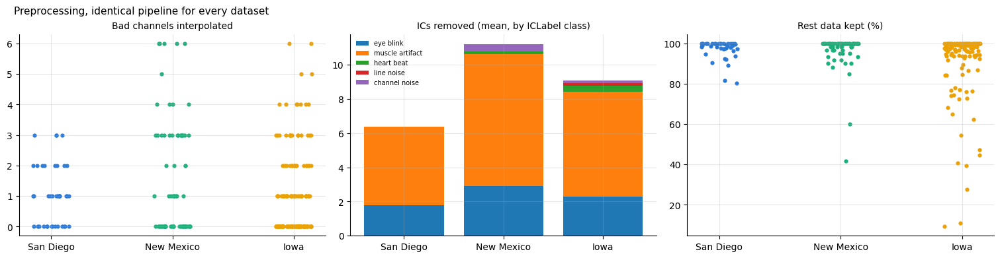

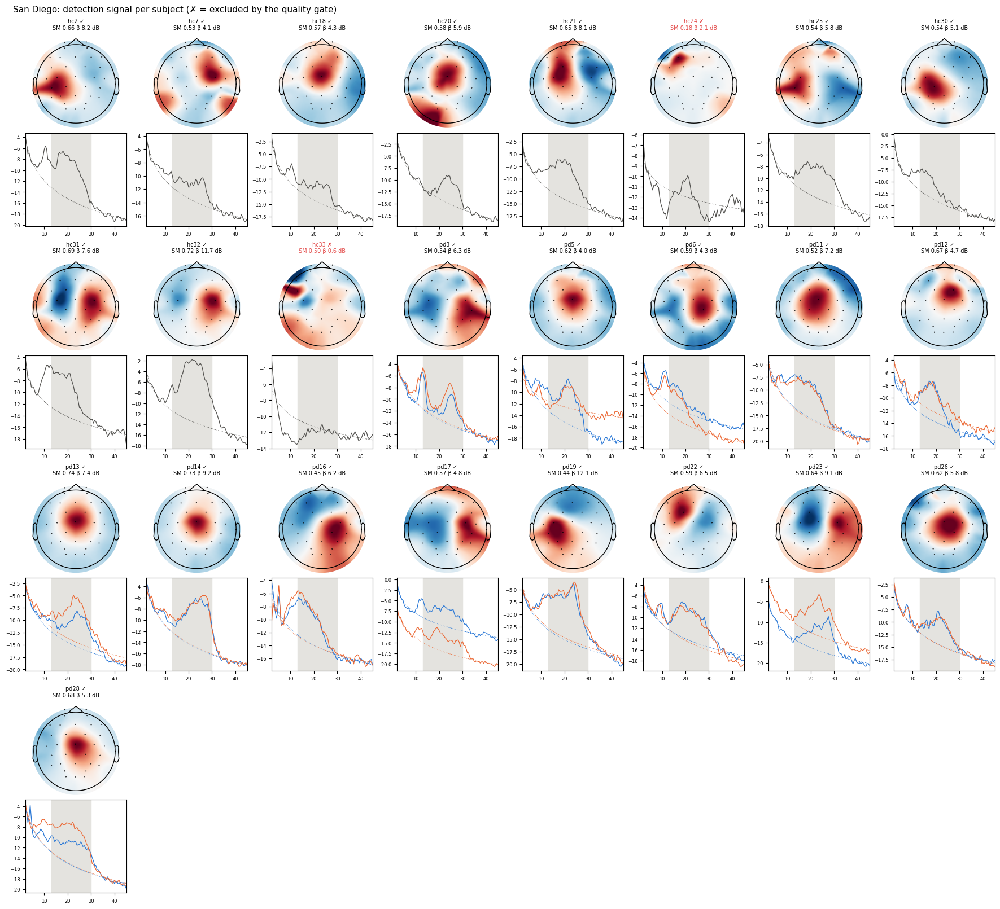

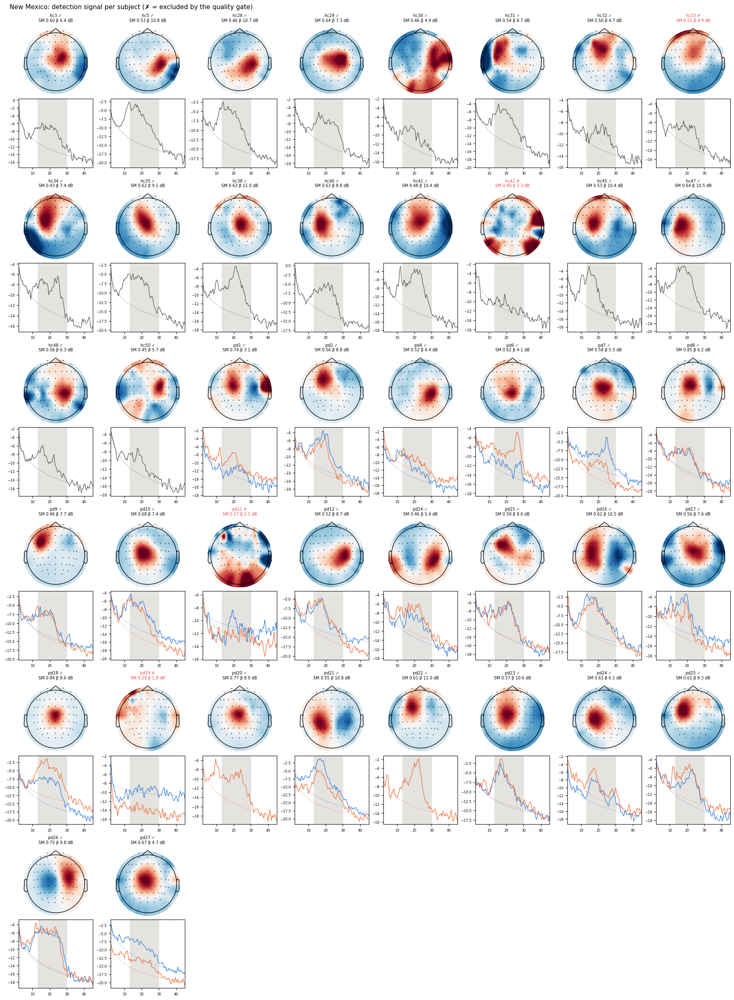

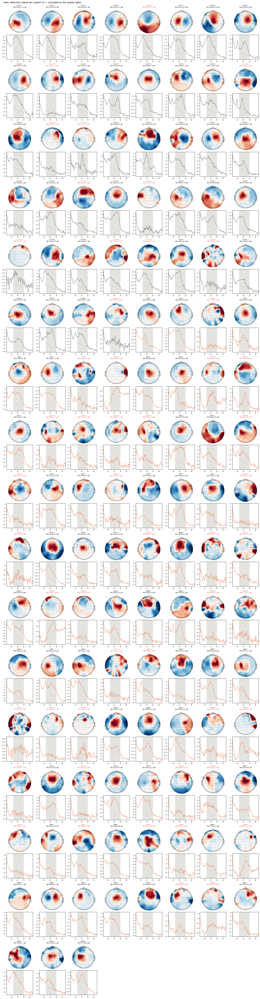

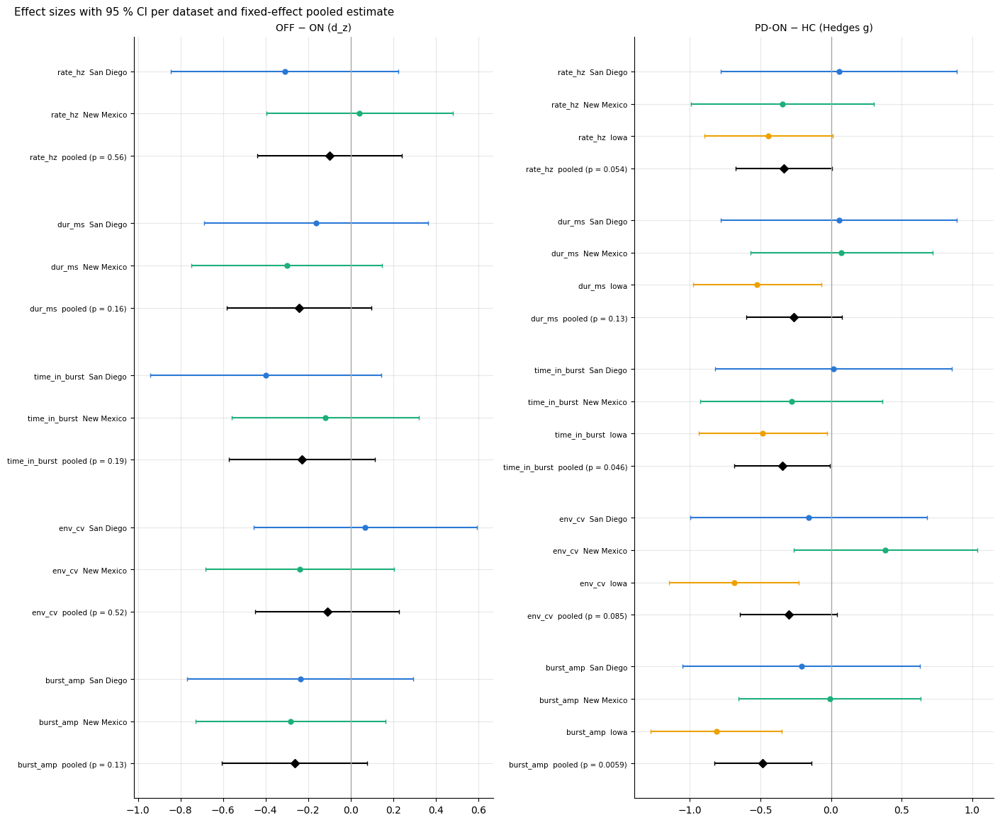

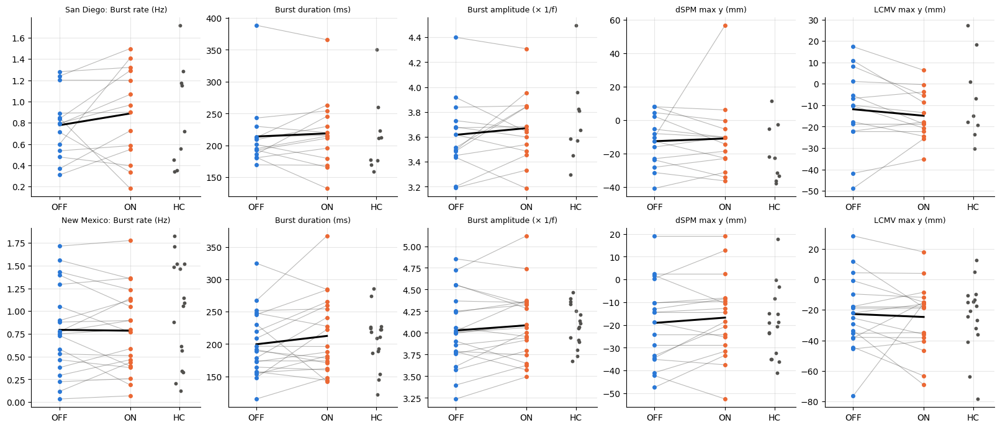

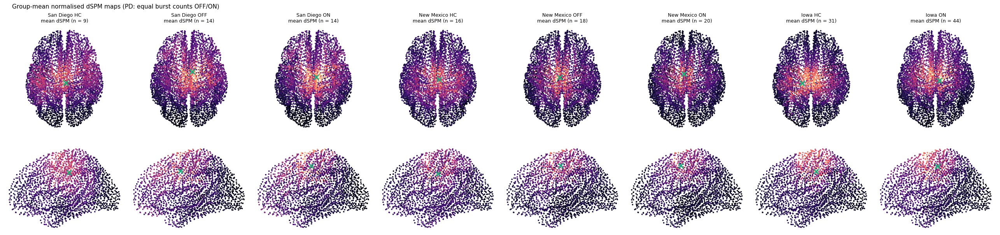

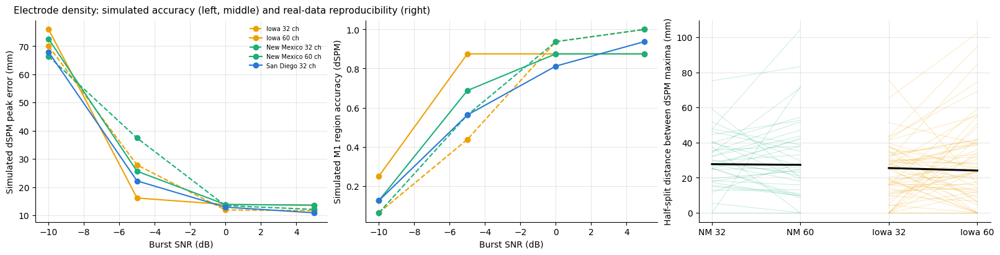

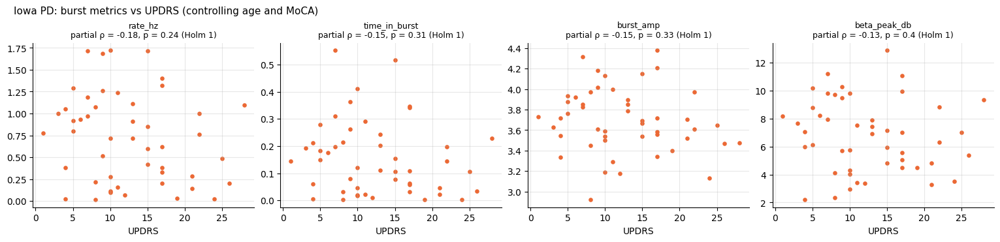

Figures: pd_beta_three\figures


In [12]:
COL = {"off": "#2a78d6", "on": "#eb6834", "hc": "#52514e"}
DS_COL = {"sandiego": "#2a78d6", "newmexico": "#1baf7a", "iowa": "#eda100"}


def style(ax):
    ax.grid(alpha=0.3)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)


def fig_preprocessing(qc_pre):
    qs = {ds: q[q.status.eq("ok")] for ds, q in qc_pre.items() if len(q)}
    fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
    for i, (ds, q) in enumerate(qs.items()):
        axs[0].scatter(np.full(len(q), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(q)), q.n_bad_channels,
                       s=12, color=DS_COL[ds])
        ic = [c for c in q if c.startswith("ic_")]
        bottom = 0
        for j, c in enumerate(ic):
            v = q[c].mean()
            axs[1].bar(i, v, bottom=bottom, color=plt.cm.tab10(j), label=c[3:].replace("_", " ") if i == 0 else None)
            bottom += v
        blk = PRIMARY_BLOCK[ds]
        if f"{blk}_bad_fraction" in q:
            axs[2].scatter(np.full(len(q), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(q)),
                           100 * (1 - q[f"{blk}_bad_fraction"]), s=12, color=DS_COL[ds])
    for ax, t in zip(axs, ("Bad channels interpolated", "ICs removed (mean, by ICLabel class)", "Rest data kept (%)")):
        ax.set_xticks(range(len(qs))); ax.set_xticklabels([LABEL[d] for d in qs]); ax.set_title(t, fontsize=10); style(ax)
    axs[1].legend(fontsize=7, frameon=False)
    fig.suptitle("Preprocessing, identical pipeline for every dataset", x=0.01, ha="left", fontsize=11)
    return fig


def fig_components(R, ds, n_cols=8):
    info = mne.create_info(R["chans"], SFREQ, "eeg")
    info.set_montage(montage_name(R["kind"]))
    subs = list(R["detectors"])
    n_rows = int(np.ceil(len(subs) / n_cols))
    fig, axs = plt.subplots(2 * n_rows, n_cols, figsize=(2.2 * n_cols, 4.0 * n_rows), constrained_layout=True, squeeze=False)
    for ax in axs.ravel():
        ax.set_axis_off()
    for i, s in enumerate(subs):
        r, c = 2 * (i // n_cols), i % n_cols
        det = R["detectors"][s]
        ax = axs[r, c]; ax.set_axis_on()
        mne.viz.plot_topomap(det["pattern"], info, axes=ax, show=False, contours=0)
        ax.set_title(f"{s} {'✓' if det['passed'] else '✗'}\nSM {det['sm_frac']:.2f} β {det['beta_db']:.1f} dB",
                     fontsize=7, color="black" if det["passed"] else "#e34948")
        ax = axs[r + 1, c]; ax.set_axis_on()
        for cond in det["conds"]:
            d = R["recs"][(s, cond)]
            f, p, fit = spectral(det["w"] @ d["X"], d["valid"], SFREQ)["curve"]
            ax.plot(f, p, color=COL[cond], lw=0.9); ax.plot(f, fit, color=COL[cond], lw=0.7, ls=":")
        ax.axvspan(13, 30, color="#e4e3df", zorder=0); ax.set_xlim(2, 45); ax.tick_params(labelsize=6)
    fig.suptitle(f"{LABEL[ds]}: detection signal per subject (✗ = excluded by the quality gate)", x=0.01, ha="left", fontsize=11)
    return fig


def fig_forest(STATS):
    ph = STATS["pd_hc"]
    blocks = [("OFF − ON (d_z)", STATS.get("offon_bursts"), "d_z", STATS.get("offon_meta")),
              ("PD-ON − HC (Hedges g)", ph[ph.contrast == "PD-ON vs HC"] if len(ph) else ph, "g", STATS.get("pd_hc_meta"))]
    fig, axs = plt.subplots(1, 2, figsize=(14, 0.5 * len(BURST) * 4 + 1.5), constrained_layout=True)
    for ax, (title, t, eff, mt) in zip(axs, blocks):
        if t is None or not len(t):
            ax.set_axis_off(); continue
        y = 0
        ticks, labels = [], []
        for m in BURST:
            d = t[t.metric == m]
            for _, r in d.iterrows():
                if not (np.isfinite(r[eff]) and np.isfinite(r["var"])):
                    continue
                se = np.sqrt(r["var"])
                ax.errorbar(r[eff], y, xerr=1.96 * se, fmt="o", color=DS_COL[r["dataset"]], ms=5, capsize=2)
                ticks.append(y); labels.append(f"{m}  {LABEL[r['dataset']]}"); y -= 1
            mt_ = mt[mt.family == "bursts"] if mt is not None and "family" in mt else mt
            if mt_ is not None and len(mt_) and (mt_.metric == m).any():
                r = mt_[mt_.metric == m].iloc[0]
                ax.errorbar(r["pooled"], y, xerr=[[r["pooled"] - r["ci_low"]], [r["ci_high"] - r["pooled"]]], fmt="D",
                            color="black", ms=6, capsize=2)
                ticks.append(y); labels.append(f"{m}  pooled (p = {r['p']:.2g})"); y -= 1
            y -= 0.6
        ax.axvline(0, color="#a8a7a2", lw=1)
        ax.set_yticks(ticks); ax.set_yticklabels(labels, fontsize=7.5); ax.set_title(title, fontsize=10); style(ax)
    fig.suptitle("Effect sizes with 95 % CI per dataset and fixed-effect pooled estimate", x=0.01, ha="left", fontsize=11)
    return fig


def fig_density(RESULTS, STATS):
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.0), constrained_layout=True)
    s = STATS["density_sim"]
    for (ds, mt), d in s[s.method == "dSPM"].groupby(["dataset", "montage"]):
        axs[0].plot(d.snr_db, d.err_mm, marker="o", color=DS_COL[ds], ls="-" if mt == "full" else "--",
                    label=f"{LABEL[ds]} {'60' if mt == 'full' and ds != 'sandiego' else '32'} ch")
    axs[0].set_xlabel("Burst SNR (dB)"); axs[0].set_ylabel("Simulated dSPM peak error (mm)"); axs[0].legend(fontsize=7, frameon=False)
    sims = pd.concat([R["sweep"] for R in RESULTS.values()])
    m1 = sims[sims.region.isin(["L_M1_hand", "R_M1_hand"]) & (sims.method == "dSPM")]
    for i, ((ds, mt), d) in enumerate(m1.groupby(["dataset", "montage"])):
        g = d.groupby("snr_db").region_correct.mean()
        axs[1].plot(g.index, g.values, marker="o", color=DS_COL[ds], ls="-" if mt == "full" else "--")
    axs[1].set_xlabel("Burst SNR (dB)"); axs[1].set_ylabel("Simulated M1 region accuracy (dSPM)")
    for i, ds in enumerate(("newmexico", "iowa")):
        if (ds, "full") in RESULTS and (ds, "bs32") in RESULTS:
            a = RESULTS[(ds, "full")]["res"].set_index(["subject", "condition"]).rel_dSPM_dist_mm
            b = RESULTS[(ds, "bs32")]["res"].set_index(["subject", "condition"]).rel_dSPM_dist_mm
            j = a.index.intersection(b.index)
            for k, (x0, x1) in enumerate(zip(b.loc[j], a.loc[j])):
                axs[2].plot([2 * i, 2 * i + 1], [x0, x1], color=DS_COL[ds], alpha=0.25, lw=0.7)
            axs[2].plot([2 * i, 2 * i + 1], [b.loc[j].median(), a.loc[j].median()], color="black", lw=2.2)
    axs[2].set_xticks([0, 1, 2, 3]); axs[2].set_xticklabels(["NM 32", "NM 60", "Iowa 32", "Iowa 60"])
    axs[2].set_ylabel("Half-split distance between dSPM maxima (mm)")
    for ax in axs:
        style(ax)
    fig.suptitle("Electrode density: simulated accuracy (left, middle) and real-data reproducibility (right)",
                 x=0.01, ha="left", fontsize=11)
    return fig


def fig_offon(full):
    dss = [ds for ds, R in full.items() if (R["res"].condition == "off").any()]
    panels = [("res", "rate_hz", "Burst rate (Hz)"), ("res", "dur_ms", "Burst duration (ms)"),
              ("res", "burst_amp", "Burst amplitude (× 1/f)"), ("matched", "dSPM_peak_y", "dSPM max y (mm)"),
              ("matched", "LCMV_peak_y", "LCMV max y (mm)")]
    fig, axs = plt.subplots(len(dss), len(panels), figsize=(3.2 * len(panels), 3.4 * len(dss)), constrained_layout=True,
                            squeeze=False)
    for i, ds in enumerate(dss):
        for j, (src, col, lab) in enumerate(panels):
            ax = axs[i, j]
            d = full[ds][src]
            if not len(d) or col not in d:
                ax.set_axis_off(); continue
            t = d[d.condition.isin(["off", "on"])].pivot_table(index="subject", columns="condition", values=col).dropna()
            for _, r in t.iterrows():
                ax.plot([0, 1], [r["off"], r["on"]], color="#52514e", alpha=0.4, lw=0.8)
            ax.scatter(np.zeros(len(t)), t["off"], color=COL["off"], s=16, zorder=3)
            ax.scatter(np.ones(len(t)), t["on"], color=COL["on"], s=16, zorder=3)
            ax.plot([0, 1], [t["off"].mean(), t["on"].mean()], color="black", lw=2.2)
            hc = full[ds]["res"]
            hc = hc[hc.condition == "hc"][col].dropna() if col in hc else []
            if len(hc):
                ax.scatter(np.full(len(hc), 1.7) + np.random.default_rng(0).uniform(-0.08, 0.08, len(hc)), hc, color=COL["hc"], s=10)
            ax.set_xticks([0, 1, 1.7]); ax.set_xticklabels(["OFF", "ON", "HC"]); ax.set_xlim(-0.4, 2.0)
            ax.set_title(f"{LABEL[ds]}: {lab}" if j == 0 else lab, fontsize=9); style(ax)
    return fig


def fig_maps(full):
    rows = [(ds, g) for ds, R in full.items() for g in ("hc", "off", "on") if len(R["mean_maps"][g])]
    n = len(rows)
    fig, axs = plt.subplots(2, n, figsize=(3.2 * n, 6.2), constrained_layout=True, squeeze=False)
    for i, (ds, g) in enumerate(rows):
        R = full[ds]
        m = np.mean(R["mean_maps"][g], axis=0)
        sim.plot_cortex(axs[0, i], R["anat"], m, "dorsal", title=f"{LABEL[ds]} {g.upper()}\nmean dSPM (n = {len(R['mean_maps'][g])})")
        sim.plot_cortex(axs[1, i], R["anat"], m, "left_lateral")
    fig.suptitle("Group-mean normalised dSPM maps (PD: equal burst counts OFF/ON)", x=0.01, ha="left", fontsize=11)
    return fig


def fig_updrs(io, up):
    ms = up.sort_values("p").metric.head(4).tolist()
    fig, axs = plt.subplots(1, len(ms), figsize=(3.8 * len(ms), 3.6), constrained_layout=True, squeeze=False)
    for ax, m in zip(axs[0], ms):
        d = io[io.group == "PD"][[m, "updrs"]].dropna()
        ax.scatter(d.updrs, d[m], s=14, color=COL["on"])
        r = up[up.metric == m].iloc[0]
        ax.set_title(f"{m}\npartial ρ = {r.partial_rho:.2f}, p = {r.p:.2g} (Holm {r.p_holm:.2g})", fontsize=9)
        ax.set_xlabel("UPDRS"); style(ax)
    fig.suptitle("Iowa PD: burst metrics vs UPDRS (controlling age and MoCA)", x=0.01, ha="left", fontsize=11)
    return fig


figs = []
if qc_pre:
    figs.append((fig_preprocessing(qc_pre), "fig1_preprocessing"))
for ds, R in full.items():
    figs.append((fig_components(R, ds), f"fig2_components_{ds}"))
figs += [(fig_forest(STATS), "fig3_effect_sizes"), (fig_offon(full), "fig4_off_on"), (fig_maps(full), "fig5_group_maps")]
if any(mt == "bs32" for _, mt in RESULTS):
    figs.append((fig_density(RESULTS, STATS), "fig6_density"))
if "iowa_updrs" in STATS and len(STATS["iowa_updrs"]):
    figs.append((fig_updrs(io, STATS["iowa_updrs"]), "fig7_iowa_updrs"))
for f, name in figs:
    f.savefig(WORK / "figures" / f"{name}.png", dpi=170)
plt.show()
print(f"Figures: {WORK / 'figures'}")